# Brick 6: Bridging Story Positions (v2 — fully reconstructed)

**WHAT THIS BRICK ANSWERS**
> *What does it mean for a film to bridge different narrative neighborhoods?*

A bridging film is NOT automatically the most famous, highest-rated, or most profitable film.  It is a film whose plot description connects story regions that would otherwise be separated — measured by betweenness centrality.

**NEW IN v2**
1. Single CONFIG dict — change parameters in one place.
2. Google Drive mount with idempotency guard (safe to re-run).
3. Vectorised degree / weighted-degree computation (no slow groupby loops).
4. `get_neighbors()` is fully vectorised (no per-row Python loop).
5. `find_node_by_title()` with 3-tier fallback: exact → substring → token overlap.
6. NEW Fig 3b — dual-axis view: raw distribution + Lorenz-style concentration.
7. NEW Fig 7b — community-reach heatmap (which bridge films span which communities).
8. NEW Fig 9  — Bridge role taxonomy: pure bridge / hybrid / peripheral.
9. Shared y-axis per row in small-multiples for honest visual comparison.
10. Profile sheets include a mini horizontal bar showing neighbour-community mix.
11. All file-not-found situations are graceful warnings, not crashes.
12. Final output manifest printed as a tidy table.

In [1]:
# ══════════════════════════════════════════════════════════════════════════════
# 0. IMPORTS
# ══════════════════════════════════════════════════════════════════════════════
import os, re, math, textwrap, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import matplotlib.patheffects as pe
import matplotlib.colors as mcolors

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 220)
pd.set_option("display.max_colwidth", 240)


In [2]:
# ══════════════════════════════════════════════════════════════════════════════
# 1. CONFIG  ← edit here, nowhere else
# ══════════════════════════════════════════════════════════════════════════════
CFG = {
    # ── paths ─────────────────────────────────────────────────────────────────
    "project_dir":   "/content/drive/MyDrive/thesis_movie_project",
    "brick_out_dir": "outputs/thesis_bricks/06_bridging_story_positions",

    # ── column-name fallback lists (first match wins) ─────────────────────────
    "node_id_cols":  ["tmdb_id", "id", "node_id", "movie_id", "imdb_id"],
    "title_cols":    ["title", "film_title", "name"],
    "year_cols":     ["release_year", "year"],
    "label_cols":    ["suggested_label_manual", "narrative_label", "label"],
    "bet_cols":      ["betweenness_centrality_sampled", "betweenness",
                       "betweenness_centrality", "bridge_score"],
    "wdeg_cols":     ["weighted_degree", "weighted_degree_from_edges"],
    "edge_src_cols": ["source", "source_id", "src", "u", "node1", "from"],
    "edge_tgt_cols": ["target", "target_id", "dst", "v", "node2", "to"],
    "edge_wt_cols":  ["weight", "similarity", "cosine", "score"],

    # ── analysis knobs ────────────────────────────────────────────────────────
    "ranked_table_n":       14,   # rows in ranked table figure
    "profile_n":             6,   # profile sheets
    "ego_n":                 3,   # local neighbourhood figures
    "ego_neighbors":        10,   # neighbours per ego-network figure
    "profile_neighbors":    10,   # neighbours used in profile sheet
    "scatter_top_n":        25,   # films shown in bridge-vs-typicality scatter
    "bridge_high_pct":      0.99, # "top 1%" threshold
    "typicality_high_pct":  0.90, # "top 10%" threshold
    "hist_bins":            50,
    "heatmap_top_bridges":  12,   # rows in community-reach heatmap
    "taxonomy_top_n":       60,   # films classified in role taxonomy
    "savefig_dpi":         320,
}


In [3]:
# ══════════════════════════════════════════════════════════════════════════════
# 2. COLOUR PALETTE & PLOT DEFAULTS
# ══════════════════════════════════════════════════════════════════════════════
COL = {
    "ink":          "#222222",
    "muted":        "#62666D",
    "grid":         "#E4E7EB",
    "panel":        "#F7F8FA",
    "blue":         "#2F6FB3",
    "orange":       "#D06C45",
    "green":        "#2F8F5B",
    "purple":       "#7A5BC2",
    "red":          "#C94C4C",
    "yellow":       "#D9A21B",
    "light_blue":   "#E8F1FB",
    "light_orange": "#FBEADF",
    "light_green":  "#E6F4EC",
    "light_purple": "#EFEAFB",
    "light_gray":   "#F2F4F7",
    "white":        "#FFFFFF",
}

COMM_COLORS = [
    "#4E79A7","#F28E2B","#59A14F","#E15759","#76B7B2","#9C755F",
    "#EDC948","#B07AA1","#FF9DA7","#BAB0AC","#2F6FB3","#D06C45",
    "#2F8F5B","#7A5BC2","#C94C4C","#D9A21B","#5C6BC0","#26A69A",
    "#AB47BC","#8D6E63","#78909C","#EC407A","#43A047","#FB8C00",
    "#6D4C41","#00ACC1",
]

plt.rcParams.update({
    "figure.facecolor":  "white",
    "axes.facecolor":    "white",
    "axes.edgecolor":    COL["ink"],
    "axes.labelcolor":   COL["ink"],
    "xtick.color":       COL["ink"],
    "ytick.color":       COL["ink"],
    "text.color":        COL["ink"],
    "font.family":       "DejaVu Sans",
    "font.size":         12,
    "axes.titlesize":    18,
    "axes.titleweight":  "bold",
    "axes.labelsize":    13,
    "xtick.labelsize":   11,
    "ytick.labelsize":   11,
    "legend.fontsize":   11,
    "savefig.dpi":       CFG["savefig_dpi"],
    "figure.dpi":        130,
})


In [4]:
# ══════════════════════════════════════════════════════════════════════════════
# 3. UTILITY FUNCTIONS
# ══════════════════════════════════════════════════════════════════════════════

def community_color(cid):
    try:    return COMM_COLORS[int(cid) % len(COMM_COLORS)]
    except: return COL["blue"]

def wrap_text(s, width=42):
    if pd.isna(s): return ""
    return "\n".join(textwrap.wrap(str(s), width=width))

def shorten(s, width=90):
    if pd.isna(s): return ""
    return textwrap.shorten(str(s).replace("\n", " "), width=width, placeholder="…")

def clean_title(x):
    if pd.isna(x): return ""
    return str(x).replace("\n", " ").strip()

def fmt_int(x):
    try:    return f"{int(round(float(x))):,}"
    except: return "—"

def fmt_float(x, d=3):
    try:    return f"{float(x):.{d}f}"
    except: return "—"

def first_col(df, candidates):
    """Return first matching column from candidates list."""
    for c in candidates:
        if c in df.columns:
            return c
    return None

def safe_read(path, label=""):
    path = Path(path)
    if path.exists():
        df = pd.read_csv(path)
        tag = f" ({label})" if label else ""
        print(f"  ✓ Loaded{tag}: {path.name}  [{df.shape[0]:,} rows × {df.shape[1]} cols]")
        return df
    print(f"  ✗ Missing{' (' + label + ')' if label else ''}: {path.name}")
    return None

def safe_int(v, default="—"):
    try:    return int(float(v)) if pd.notna(v) else default
    except: return default


# ══════════════════════════════════════════════════════════════════════════════
# 4. FIGURE / IO HELPERS
# ══════════════════════════════════════════════════════════════════════════════

def save_fig(fig, name, dpi=None):
    dpi = dpi or CFG["savefig_dpi"]
    for ext in (".png", ".svg"):
        p = FIG_DIR / name.replace(".png", ext)
        fig.savefig(p, dpi=dpi, bbox_inches="tight", facecolor="white")
    print(f"  ✓ Saved: {name}")

def save_table(df, name):
    p = TABLE_DIR / name
    df.to_csv(p, index=False, encoding="utf-8")
    print(f"  ✓ Saved table: {name}  [{len(df):,} rows]")
    return p

def write_text(txt, name):
    p = TEXT_DIR / name
    p.write_text(txt, encoding="utf-8")
    print(f"  ✓ Saved text: {name}")
    return p

def title_block(fig, title, subtitle=None, x=0.05, y=0.965):
    fig.text(x, y,        title,    ha="left", va="top", fontsize=22,   fontweight="bold", color=COL["ink"])
    if subtitle:
        fig.text(x, y-0.055, subtitle, ha="left", va="top", fontsize=12.5, color=COL["muted"])

def draw_card(ax, x0, y0, w, h, value, label, bg, fontsize_val=18):
    """Reusable stat card drawn on axes in axes-transform coordinates."""
    ax.add_patch(FancyBboxPatch(
        (x0, y0), w, h,
        boxstyle="round,pad=0.018,rounding_size=0.02",
        facecolor=bg, edgecolor="none", transform=ax.transAxes))
    ax.text(x0+w/2, y0+h*0.60, value, transform=ax.transAxes,
            ha="center", va="center", fontsize=fontsize_val, fontweight="bold")
    ax.text(x0+w/2, y0+h*0.22, label, transform=ax.transAxes,
            ha="center", va="center", fontsize=10.5, color=COL["muted"])


In [5]:
# ══════════════════════════════════════════════════════════════════════════════
# 5. GOOGLE DRIVE MOUNT
# ══════════════════════════════════════════════════════════════════════════════

print("── Google Drive ──────────────────────────────────────────────────────")
try:
    from google.colab import drive
    if Path("/content/drive/MyDrive").exists():
        print("  Drive already mounted — skipping.")
    else:
        drive.mount("/content/drive")
        print("  Drive mounted successfully.")
except Exception as e:
    print(f"  Drive mount skipped (not in Colab or already mounted): {e}")


# ══════════════════════════════════════════════════════════════════════════════
# 6. PROJECT PATHS
# ══════════════════════════════════════════════════════════════════════════════

PROJECT_DIR           = Path(CFG["project_dir"]).resolve()
PROCESSED_NETWORK_DIR = PROJECT_DIR / "processed" / "network"
OUTPUT_TABLES_DIR     = PROJECT_DIR / "outputs"   / "tables"

FINAL_DIR = PROJECT_DIR / CFG["brick_out_dir"]
FIG_DIR   = FINAL_DIR / "figures"
TABLE_DIR = FINAL_DIR / "tables"
TEXT_DIR  = FINAL_DIR / "text"

for d in [FINAL_DIR, FIG_DIR, TABLE_DIR, TEXT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"\n  PROJECT_DIR : {PROJECT_DIR}")
print(f"  OUTPUT DIR  : {FINAL_DIR}")


── Google Drive ──────────────────────────────────────────────────────
Mounted at /content/drive
  Drive mounted successfully.

  PROJECT_DIR : /content/drive/MyDrive/thesis_movie_project
  OUTPUT DIR  : /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/06_bridging_story_positions


In [6]:
# ══════════════════════════════════════════════════════════════════════════════
# 7. LOAD FILES
# ══════════════════════════════════════════════════════════════════════════════

print("\n── Loading files ─────────────────────────────────────────────────────")

FILES = {
    "nodes":                     PROCESSED_NETWORK_DIR / "semantic_network_nodes_lcc.csv",
    "edges":                     PROCESSED_NETWORK_DIR / "semantic_network_edges_mutual_knn.csv",
    "community_labels":          OUTPUT_TABLES_DIR / "community_manual_labeling_template_labeled.csv",
    "bridging_visible":          OUTPUT_TABLES_DIR / "top_betweenness_visible_franchise_capped.csv",
    "bridging_basic":            OUTPUT_TABLES_DIR / "bridging_films_betweenness.csv",
    "top_visible_central":       OUTPUT_TABLES_DIR / "top_visible_central_films_per_community.csv",
    "top_weighted_degree_visible":OUTPUT_TABLES_DIR / "top_weighted_degree_visible_franchise_capped.csv",
}

nodes               = safe_read(FILES["nodes"],               "nodes")
edges               = safe_read(FILES["edges"],               "edges")
community_labels    = safe_read(FILES["community_labels"],    "community_labels")
bridging_visible    = safe_read(FILES["bridging_visible"],    "bridging_visible")
bridging_basic      = safe_read(FILES["bridging_basic"],      "bridging_basic")
top_visible_central = safe_read(FILES["top_visible_central"], "top_visible_central")
top_wdeg_visible    = safe_read(FILES["top_weighted_degree_visible"], "top_wdeg_visible")

if nodes is None or edges is None:
    print("\n[WARNING] Brick 6 requires semantic_network_nodes_lcc.csv and semantic_network_edges_mutual_knn.csv to run fully.")
else:
    # ── detect column names ───────────────────────────────────────────────────────
    source_col  = first_col(edges, CFG["edge_src_cols"]) or edges.columns[0]
    target_col  = first_col(edges, CFG["edge_tgt_cols"]) or edges.columns[1]
    weight_col  = first_col(edges, CFG["edge_wt_cols"])
    node_id_col = first_col(nodes, CFG["node_id_cols"]) or nodes.columns[0]
    title_col   = first_col(nodes, CFG["title_cols"])   or nodes.columns[0]
    year_col    = first_col(nodes, CFG["year_cols"])

    print(f"\n  Cols detected — node_id:{node_id_col}  title:{title_col}  "
          f"year:{year_col}  src:{source_col}  tgt:{target_col}  wt:{weight_col}")

    # ── attach community narrative labels ─────────────────────────────────────────
    label_col = label_lookup = None
    if community_labels is not None:
        label_col = first_col(community_labels, CFG["label_cols"])
        if label_col and "community_id" in community_labels.columns:
            label_lookup = (
                community_labels[["community_id", label_col]]
                .drop_duplicates()
                .rename(columns={label_col: "narrative_label"})
            )
            if "narrative_label" not in nodes.columns and "community_id" in nodes.columns:
                nodes = nodes.merge(label_lookup, on="community_id", how="left")
            for name in ["bridging_visible","bridging_basic","top_visible_central","top_wdeg_visible"]:
                df = globals()[name]
                if df is not None and "community_id" in df.columns and "narrative_label" not in df.columns:
                    globals()[name] = df.merge(label_lookup, on="community_id", how="left")



── Loading files ─────────────────────────────────────────────────────
  ✓ Loaded (nodes): semantic_network_nodes_lcc.csv  [19,202 rows × 30 cols]
  ✓ Loaded (edges): semantic_network_edges_mutual_knn.csv  [86,685 rows × 9 cols]
  ✓ Loaded (community_labels): community_manual_labeling_template_labeled.csv  [23 rows × 15 cols]
  ✓ Loaded (bridging_visible): top_betweenness_visible_franchise_capped.csv  [50 rows × 12 cols]
  ✓ Loaded (bridging_basic): bridging_films_betweenness.csv  [100 rows × 12 cols]
  ✓ Loaded (top_visible_central): top_visible_central_films_per_community.csv  [77 rows × 12 cols]
  ✓ Loaded (top_wdeg_visible): top_weighted_degree_visible_franchise_capped.csv  [50 rows × 12 cols]

  Cols detected — node_id:tmdb_id  title:title  year:release_year  src:source_node_id  tgt:target_node_id  wt:None


## Graph Metrics & Helper Setup

In [8]:
if nodes is not None and edges is not None:
    # ══════════════════════════════════════════════════════════════════════════════
    # 8. BUILD GRAPH METRICS  (vectorised)
    # ══════════════════════════════════════════════════════════════════════════════

    print("\n── Computing graph metrics ───────────────────────────────────────────")

    # Standardise edge table
    edge_tmp = edges[[source_col, target_col] + ([weight_col] if weight_col else [])].copy()
    edge_tmp.columns = ["source_id", "target_id"] + (["edge_weight"] if weight_col else [])
    if "edge_weight" not in edge_tmp.columns:
        edge_tmp["edge_weight"] = 1.0
    # Ensure consistent types
    edge_tmp["source_id"] = edge_tmp["source_id"].astype(str)
    edge_tmp["target_id"] = edge_tmp["target_id"].astype(str)

    # Vectorised degree + weighted degree
    long = pd.concat([
        edge_tmp[["source_id","edge_weight"]].rename(columns={"source_id":"node_id"}),
        edge_tmp[["target_id","edge_weight"]].rename(columns={"target_id":"node_id"}),
    ])
    agg = long.groupby("node_id")["edge_weight"].agg(
        degree_from_edges="count",
        weighted_degree_from_edges="sum",
    ).reset_index().rename(columns={"node_id": node_id_col})
    agg[node_id_col] = agg[node_id_col].astype(nodes[node_id_col].dtype)

    bridge_nodes = nodes.merge(agg, on=node_id_col, how="left")
    bridge_nodes[["degree_from_edges","weighted_degree_from_edges"]] = (
        bridge_nodes[["degree_from_edges","weighted_degree_from_edges"]].fillna(0)
    )

    # Pick betweenness column
    bet_col = first_col(bridge_nodes, CFG["bet_cols"])
    if bet_col:
        bridge_nodes["bridge_score"]      = bridge_nodes[bet_col]
        bridge_nodes["bridge_score_norm"] = (
            (bridge_nodes["bridge_score"] - bridge_nodes["bridge_score"].min()) /
            (bridge_nodes["bridge_score"].max() - bridge_nodes["bridge_score"].min() + 1e-12)
        )
        bridge_nodes["bridge_percentile"] = bridge_nodes["bridge_score"].rank(pct=True, method="min")
        print(f"  Betweenness column: '{bet_col}'")
    else:
        print("  ⚠  No betweenness column found — bridge_score will be NaN.")
        bridge_nodes["bridge_score"]      = np.nan
        bridge_nodes["bridge_score_norm"] = np.nan
        bridge_nodes["bridge_percentile"] = np.nan

    # Typicality = weighted degree (normalised)
    wdeg_col = first_col(bridge_nodes, CFG["wdeg_cols"])
    if wdeg_col:
        wd = bridge_nodes[wdeg_col]
        bridge_nodes["typicality_score"]      = wd
        bridge_nodes["typicality_score_norm"] = (wd - wd.min()) / (wd.max() - wd.min() + 1e-12)
    else:
        bridge_nodes["typicality_score"]      = bridge_nodes["weighted_degree_from_edges"]
        wd = bridge_nodes["typicality_score"]
        bridge_nodes["typicality_score_norm"] = (wd - wd.min()) / (wd.max() - wd.min() + 1e-12)

    # Node lookup (O(1) access)
    nodes[node_id_col] = nodes[node_id_col].astype(str)
    bridge_nodes[node_id_col] = bridge_nodes[node_id_col].astype(str)
    node_lookup = bridge_nodes.set_index(node_id_col, drop=False)

    save_table(bridge_nodes, "00_bridge_node_diagnostics.csv")
    print(f"\n  Bridge diagnostics built for {len(bridge_nodes):,} nodes.")
    print(bridge_nodes[["bridge_score","bridge_score_norm","typicality_score_norm"]].describe().round(4))


    # ══════════════════════════════════════════════════════════════════════════════
    # 9. LOOKUP & NEIGHBOUR HELPERS
    # ══════════════════════════════════════════════════════════════════════════════

    def film_info(node_id, field, default="—"):
        nid = str(node_id)
        if nid in node_lookup.index:
            v = node_lookup.loc[nid].get(field, default)
            return default if pd.isna(v) else v
        return default

    def film_title(node_id):  return clean_title(film_info(node_id, title_col, node_id))
    def film_year(node_id):   return safe_int(film_info(node_id, year_col or "release_year", "—"))
    def film_community(node_id): return safe_int(film_info(node_id, "community_id", "—"))
    def film_label(node_id):  return str(film_info(node_id, "narrative_label", ""))

    def find_node_by_title(title):
        """3-tier match: exact → substring → token-overlap ≥ 0.5."""
        if not title:
            return None
        t = str(title).strip().lower()
        titles_lower = bridge_nodes[title_col].astype(str).str.strip().str.lower()
        # 1. exact
        hit = bridge_nodes[titles_lower == t]
        if len(hit): return hit.iloc[0]
        # 2. substring
        hit = bridge_nodes[titles_lower.str.contains(re.escape(t), na=False)]
        if len(hit): return hit.iloc[0]
        # 3. token overlap
        qt = set(t.split())
        scores = titles_lower.apply(lambda s: len(qt & set(s.split())) / max(len(qt), 1))
        best   = scores.idxmax()
        if scores[best] >= 0.5: return bridge_nodes.loc[best]
        return None

    def get_neighbors(anchor_id, top_n=10):
        """Return top-N neighbours — fully vectorised."""
        aid  = str(anchor_id)
        mask = (edge_tmp["source_id"] == aid) | (edge_tmp["target_id"] == aid)
        sub  = edge_tmp[mask].copy()
        if sub.empty: return pd.DataFrame()
        sub["neighbor_id"] = np.where(sub["source_id"] == aid, sub["target_id"], sub["source_id"])
        sub = sub.nlargest(top_n, "edge_weight")

        info_cols = {
            title_col:          "neighbor_title",
            year_col or "release_year": "neighbor_year",
            "community_id":     "neighbor_community",
            "narrative_label":  "neighbor_label",
            "bridge_score":     "neighbor_bridge_score",
            "typicality_score": "neighbor_typicality",
        }
        avail = {k: v for k, v in info_cols.items() if k in bridge_nodes.columns}
        ninfo = bridge_nodes.set_index(node_id_col)[list(avail.keys())].rename(columns=avail)
        result = sub.merge(ninfo, left_on="neighbor_id", right_index=True, how="left")
        result.insert(0, "anchor_id", aid)
        return result.reset_index(drop=True)

    # ══════════════════════════════════════════════════════════════════════════════
    # 10. BUILD BRIDGE SOURCE  (choose best available ranked list)
    # ══════════════════════════════════════════════════════════════════════════════

    print("\n── Building bridge source ────────────────────────────────────────────")

    bridge_source = None
    for df in [bridging_visible, bridging_basic]:
        if df is not None and len(df):
            bridge_source = df.copy()
            print(f"  Using pre-computed bridging table ({len(bridge_source):,} rows).")
            break

    if bridge_source is None:
        if bet_col:
            bridge_source = bridge_nodes.sort_values("bridge_score", ascending=False).copy()
            print("  No pre-computed table — using nodes sorted by bridge_score.")
        else:
            # Fallback to empty if absolutely nothing
            bridge_source = bridge_nodes.copy()

    # Attach node IDs (batch map avoids per-row loop)
    bridge_source[node_id_col] = bridge_source[node_id_col].astype(str) \
        if node_id_col in bridge_source.columns else np.nan

    if node_id_col not in bridge_source.columns or bridge_source[node_id_col].isna().all():
        t_lower   = bridge_source.get("title", bridge_source.iloc[:,0]).astype(str).str.strip().str.lower()

        # Ensure the id_map has a unique index to avoid InvalidIndexError
        # This assumes that if there are duplicate titles, keeping the first node_id is acceptable.
        temp_bridge_nodes = bridge_nodes[[title_col, node_id_col]].copy()
        temp_bridge_nodes[title_col] = temp_bridge_nodes[title_col].astype(str).str.strip().str.lower()
        temp_bridge_nodes = temp_bridge_nodes.drop_duplicates(subset=[title_col])

        id_map = temp_bridge_nodes.set_index(title_col)[node_id_col]
        bridge_source[node_id_col] = t_lower.map(id_map)

    bridge_source = bridge_source.dropna(subset=[node_id_col]).copy()
    bridge_source[node_id_col] = bridge_source[node_id_col].astype(str)

    # Attach scores from node table
    score_cols_needed = [c for c in ["bridge_score","bridge_score_norm","bridge_percentile",
                                      "typicality_score","typicality_score_norm",
                                      "degree_from_edges","weighted_degree_from_edges"]
                         if c not in bridge_source.columns]
    if score_cols_needed:
        bridge_source = bridge_source.merge(
            bridge_nodes[[node_id_col] + score_cols_needed],
            on=node_id_col, how="left", suffixes=("","_node"))

    save_table(bridge_source, "00_bridge_source_for_figures.csv")
    display(bridge_source.head(5))


── Computing graph metrics ───────────────────────────────────────────
  Betweenness column: 'betweenness_centrality_sampled'
  ✓ Saved table: 00_bridge_node_diagnostics.csv  [19,202 rows]

  Bridge diagnostics built for 19,202 nodes.
       bridge_score  bridge_score_norm  typicality_score_norm
count    19202.0000         19202.0000             19202.0000
mean         0.0002             0.1023                 0.3085
std          0.0002             0.1023                 0.1960
min          0.0000             0.0000                 0.0000
25%          0.0001             0.0267                 0.1498
50%          0.0002             0.0720                 0.2798
75%          0.0003             0.1469                 0.4389
max          0.0022             1.0000                 1.0000

── Building bridge source ────────────────────────────────────────────
  Using pre-computed bridging table (50 rows).
  ✓ Saved table: 00_bridge_source_for_figures.csv  [50 rows]


,title,release_year,primary_genre,vote_count,vote_average,community_id,degree,weighted_degree,pagerank,betweenness_centrality_sampled,eigenvector_centrality,clustering_coefficient,narrative_label,tmdb_id,bridge_score,bridge_score_norm,bridge_percentile,typicality_score,typicality_score_norm,degree_from_edges,weighted_degree_from_edges
0,The Bandit,1996,Crime,355.0,7.3,22,18,9.672851,0.000093,0.002223,0.000004,0.003452,"Relationship drama, romantic comedy, and emotional-family crossover",26900,0.002223,1.000000,1.000000,9.672851,0.660163,0.0,0.0
1,The TV Set,2007,Comedy,89.0,6.0,6,13,6.224862,0.000077,0.002018,0.000002,0.104251,"Identity crisis, family/home disruption, and adult-life thriller-comedy",17320,0.002018,0.907704,0.999948,6.224862,0.416339,13.0,13.0
2,Ace Ventura: When Nature Calls,1995,Crime,4524.0,6.3,10,14,6.649705,0.000078,0.001957,0.000001,0.016134,"Adventure spectacle, creature threat, and family-animation peril",9273,0.001957,0.880345,0.999896,6.649705,0.446381,10.0,10.0
3,Intacto,2001,Action,196.0,6.6,23,18,9.807808,0.000094,0.001868,0.000007,0.021826,"Crime, heist, revenge, and underworld action",10856,0.001868,0.840592,0.999792,9.807808,0.669706,8.0,8.0
4,The Perfect Weapon,1991,Action,124.0,6.2,10,16,8.534136,0.000098,0.001788,0.000004,0.018160,"Adventure spectacle, creature threat, and family-animation peril",34421,0.001788,0.804420,0.999740,8.534136,0.579639,0.0,0.0


## Figures 1 - 3


── Fig 1: Narrative brokerage diagram ───────────────────────────────
  ✓ Saved: 01_bridging_as_narrative_brokerage.png


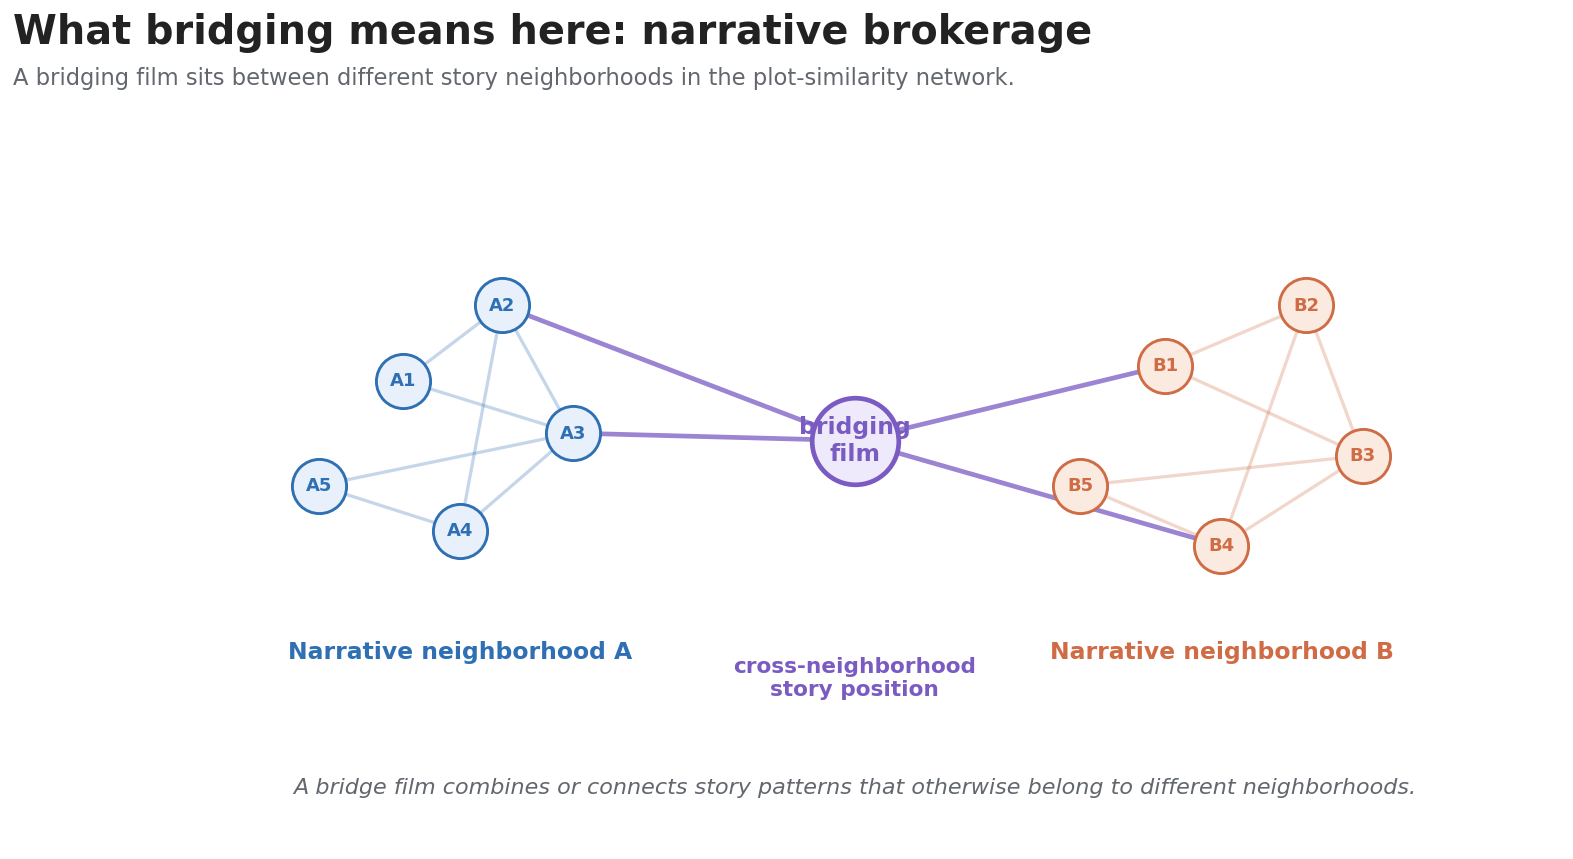


── Fig 2: Betweenness explainer ─────────────────────────────────────
  ✓ Saved: 02_betweenness_explainer.png


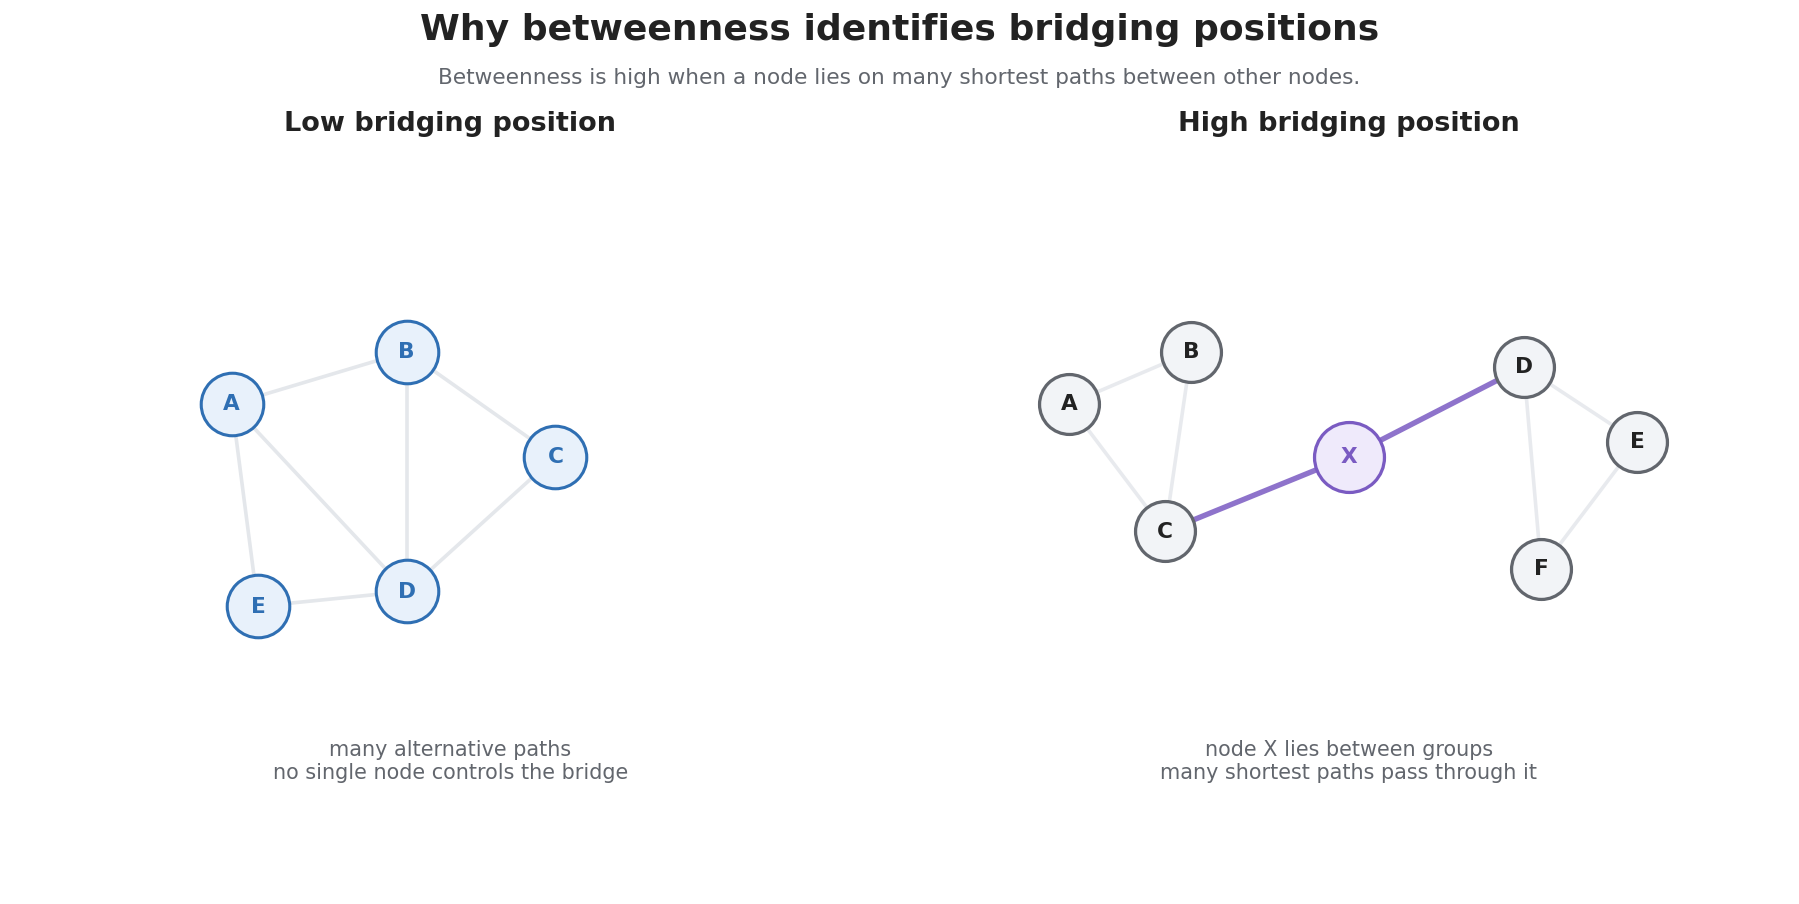


── Fig 3a: Betweenness distribution ─────────────────────────────────
  ✓ Saved table: 03_betweenness_distribution_summary.csv  [11 rows]
  ✓ Saved: 03a_betweenness_distribution.png


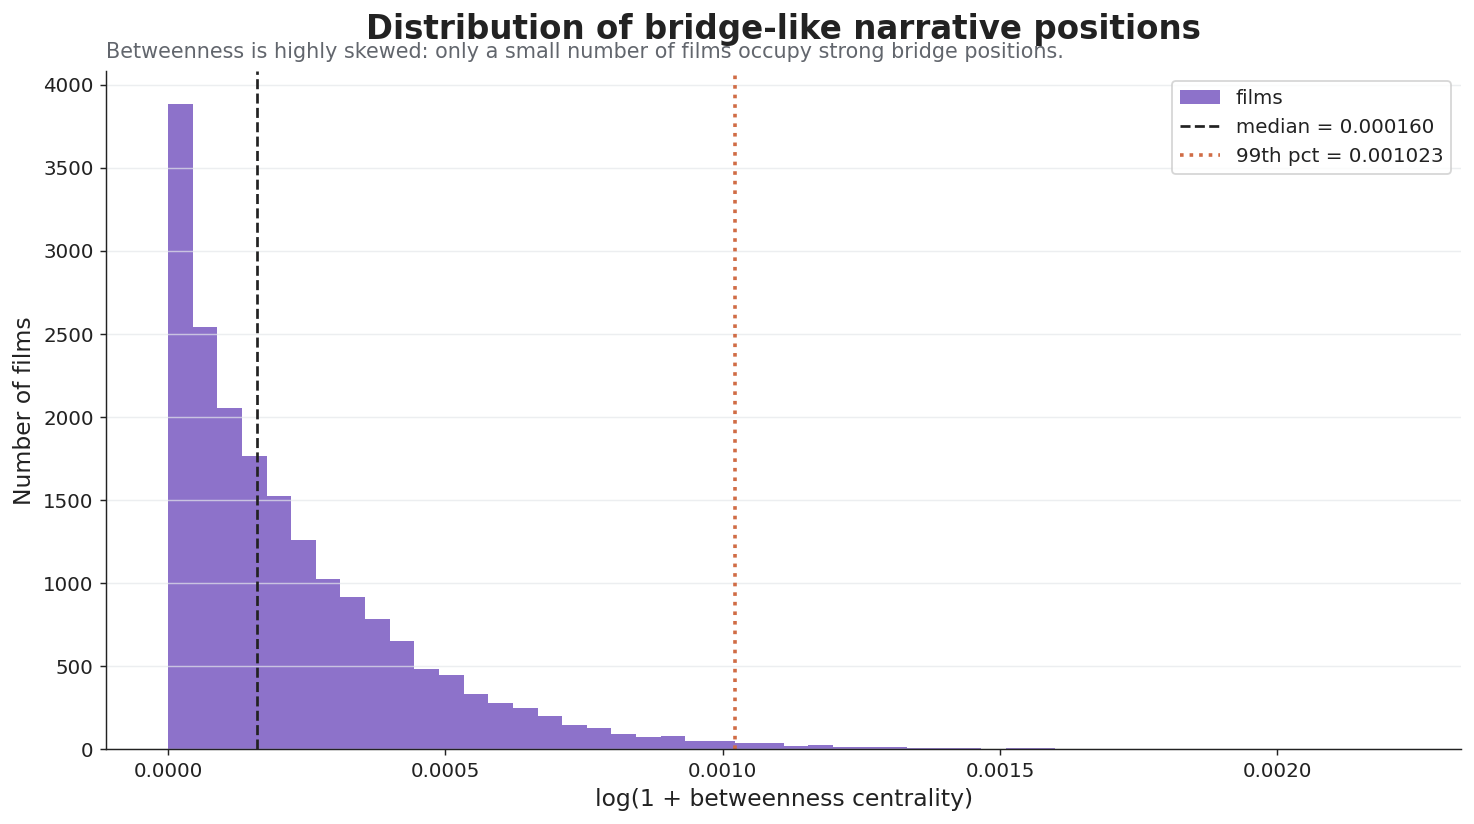


── Fig 3b: Betweenness concentration (NEW) ──────────────────────────
  ✓ Saved: 03b_betweenness_concentration.png


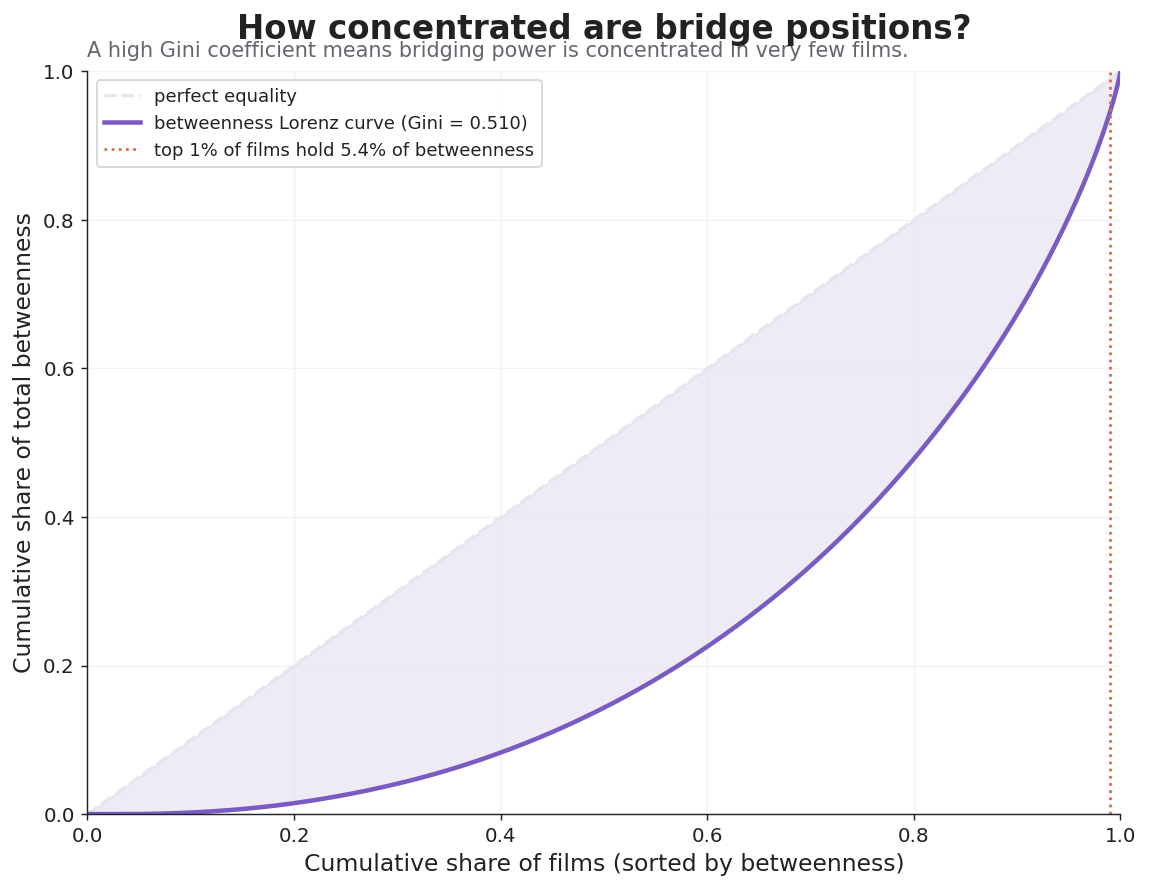

In [9]:
if nodes is not None and edges is not None:
    # ══════════════════════════════════════════════════════════════════════════════
    # 11. FIGURE 1 — Bridging as narrative brokerage  (conceptual diagram)
    # ══════════════════════════════════════════════════════════════════════════════

    print("\n── Fig 1: Narrative brokerage diagram ───────────────────────────────")

    fig, ax = plt.subplots(figsize=(14, 7.5))
    ax.axis("off"); ax.set_xlim(0,1); ax.set_ylim(0,1)
    title_block(fig,
        "What bridging means here: narrative brokerage",
        "A bridging film sits between different story neighborhoods in the plot-similarity network.")

    left_nodes  = [(0.18,0.62),(0.25,0.72),(0.30,0.55),(0.22,0.42),(0.12,0.48)]
    right_nodes = [(0.72,0.64),(0.82,0.72),(0.86,0.52),(0.76,0.40),(0.66,0.48)]
    bridge      = (0.50,0.54)

    # Internal community links
    for group, col in [(left_nodes, COL["blue"]), (right_nodes, COL["orange"])]:
        for i,(x1,y1) in enumerate(group):
            for j,(x2,y2) in enumerate(group):
                if i < j and abs(i-j) <= 2:
                    ax.plot([x1,x2],[y1,y2], color=col, lw=1.8, alpha=0.28, zorder=1)

    # Bridge links (purple, thicker)
    for x,y in [left_nodes[1], left_nodes[2], right_nodes[0], right_nodes[3]]:
        ax.plot([bridge[0],x],[bridge[1],y], color=COL["purple"], lw=2.6, alpha=0.75, zorder=2)

    # Community nodes
    for i,(x,y) in enumerate(left_nodes):
        ax.scatter(x,y, s=900, color=COL["light_blue"], edgecolor=COL["blue"], lw=1.6, zorder=3)
        ax.text(x,y, f"A{i+1}", ha="center", va="center", fontsize=10,
                fontweight="bold", color=COL["blue"], zorder=4)
    for i,(x,y) in enumerate(right_nodes):
        ax.scatter(x,y, s=900, color=COL["light_orange"], edgecolor=COL["orange"], lw=1.6, zorder=3)
        ax.text(x,y, f"B{i+1}", ha="center", va="center", fontsize=10,
                fontweight="bold", color=COL["orange"], zorder=4)

    # Bridge node
    ax.scatter(*bridge, s=2300, color=COL["light_purple"], edgecolor=COL["purple"], lw=2.6, zorder=5)
    ax.text(*bridge, "bridging\nfilm", ha="center", va="center", fontsize=13,
            fontweight="bold", color=COL["purple"], zorder=6)

    ax.text(0.22,0.25,"Narrative neighborhood A", ha="center", fontsize=13,
            fontweight="bold", color=COL["blue"])
    ax.text(0.76,0.25,"Narrative neighborhood B", ha="center", fontsize=13,
            fontweight="bold", color=COL["orange"])
    ax.text(0.50,0.20,"cross-neighborhood\nstory position", ha="center", fontsize=12,
            fontweight="bold", color=COL["purple"])
    ax.text(0.5,0.07,
        "A bridge film combines or connects story patterns that otherwise belong to different neighborhoods.",
        ha="center", fontsize=12.3, color=COL["muted"], style="italic")

    save_fig(fig,"01_bridging_as_narrative_brokerage.png"); plt.show()

    # ══════════════════════════════════════════════════════════════════════════════
    # 12. FIGURE 2 — Betweenness explainer (low vs. high position)
    # ══════════════════════════════════════════════════════════════════════════════

    print("\n── Fig 2: Betweenness explainer ─────────────────────────────────────")

    fig, axes = plt.subplots(1, 2, figsize=(14, 6.8))
    fig.suptitle("Why betweenness identifies bridging positions",
                 fontsize=20, fontweight="bold", y=1.02)
    fig.text(0.5, 0.94,
        "Betweenness is high when a node lies on many shortest paths between other nodes.",
        ha="center", fontsize=12, color=COL["muted"])

    # ── left panel: low betweenness ────────────────────────────────────────────────
    ax = axes[0]; ax.axis("off"); ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_title("Low bridging position", fontsize=15, fontweight="bold")
    pos1 = {"A":(0.25,0.65),"B":(0.45,0.72),"C":(0.62,0.58),"D":(0.45,0.40),"E":(0.28,0.38)}
    edges1 = [("A","B"),("B","C"),("C","D"),("D","E"),("E","A"),("A","D"),("B","D")]
    for u,v in edges1:
        ax.plot([pos1[u][0],pos1[v][0]],[pos1[u][1],pos1[v][1]], color=COL["grid"], lw=2)
    for k,(x,y) in pos1.items():
        ax.scatter(x,y,s=1200,color=COL["light_blue"],edgecolor=COL["blue"],lw=1.7,zorder=3)
        ax.text(x,y,k,ha="center",va="center",fontsize=12,fontweight="bold",color=COL["blue"],zorder=4)
    ax.text(0.5,0.15,"many alternative paths\nno single node controls the bridge",
            ha="center", fontsize=11.5, color=COL["muted"])

    # ── right panel: high betweenness ─────────────────────────────────────────────
    ax = axes[1]; ax.axis("off"); ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_title("High bridging position", fontsize=15, fontweight="bold")
    pos2 = {
        "A":(0.18,0.65),"B":(0.32,0.72),"C":(0.29,0.48),
        "X":(0.50,0.58),
        "D":(0.70,0.70),"E":(0.83,0.60),"F":(0.72,0.43)
    }
    edges2 = [("A","B"),("A","C"),("B","C"),("C","X"),("X","D"),("D","E"),("D","F"),("E","F")]
    for u,v in edges2:
        col = COL["purple"] if "X" in [u,v] else COL["grid"]
        lw  = 3.0           if "X" in [u,v] else 2.0
        ax.plot([pos2[u][0],pos2[v][0]],[pos2[u][1],pos2[v][1]], color=col, lw=lw, alpha=0.85)
    for k,(x,y) in pos2.items():
        face = COL["light_purple"] if k=="X" else COL["light_gray"]
        edgc = COL["purple"]       if k=="X" else COL["muted"]
        tcol = COL["purple"]       if k=="X" else COL["ink"]
        size = 1500                if k=="X" else 1100
        ax.scatter(x,y,s=size,color=face,edgecolor=edgc,lw=1.8,zorder=3)
        ax.text(x,y,k,ha="center",va="center",fontsize=12,fontweight="bold",color=tcol,zorder=4)
    ax.text(0.5,0.15,"node X lies between groups\nmany shortest paths pass through it",
            ha="center", fontsize=11.5, color=COL["muted"])

    plt.tight_layout()
    save_fig(fig,"02_betweenness_explainer.png"); plt.show()

    # ══════════════════════════════════════════════════════════════════════════════
    # 13. FIGURE 3a — Betweenness distribution
    # ══════════════════════════════════════════════════════════════════════════════

    print("\n── Fig 3a: Betweenness distribution ─────────────────────────────────")

    if bridge_nodes["bridge_score"].notna().any():
        x     = bridge_nodes["bridge_score"].dropna()
        x_log = np.log1p(x)

        pcts    = [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
        summary = pd.DataFrame({
            "metric": ["n","min","median","mean"] + [f"p{int(p*100)}" for p in pcts] + ["max"],
            "value":  [len(x), x.min(), x.median(), x.mean()] +
                      [x.quantile(p) for p in pcts] + [x.max()]
        })
        save_table(summary,"03_betweenness_distribution_summary.csv")

        fig, ax = plt.subplots(figsize=(11.5, 6.5))
        ax.hist(x_log, bins=CFG["hist_bins"], color=COL["purple"], alpha=0.86, label="films")
        ax.axvline(np.log1p(x.median()),       color=COL["ink"],    ls="--", lw=1.5,
                   label=f"median = {x.median():.6f}")
        ax.axvline(np.log1p(x.quantile(.99)), color=COL["orange"], ls=":",  lw=2.0,
                   label=f"99th pct = {x.quantile(.99):.6f}")

        ax.set_title("Distribution of bridge-like narrative positions", pad=18)
        ax.text(0,1.02,
            "Betweenness is highly skewed: only a small number of films occupy strong bridge positions.",
            transform=ax.transAxes, fontsize=11.5, color=COL["muted"])
        ax.set_xlabel("log(1 + betweenness centrality)")
        ax.set_ylabel("Number of films")
        ax.spines[["top","right"]].set_visible(False)
        ax.grid(axis="y", color=COL["grid"], alpha=0.7)
        ax.legend()
        plt.tight_layout()
        save_fig(fig,"03a_betweenness_distribution.png"); plt.show()
    else:
        print("  ⚠  Skipped — no bridge_score data.")

    # ══════════════════════════════════════════════════════════════════════════════
    # 14. FIGURE 3b — NEW: Betweenness concentration (Lorenz-style)
    # ══════════════════════════════════════════════════════════════════════════════

    print("\n── Fig 3b: Betweenness concentration (NEW) ──────────────────────────")

    if bridge_nodes["bridge_score"].notna().any():
        sorted_scores = bridge_nodes["bridge_score"].fillna(0).sort_values().values
        cum_share     = np.cumsum(sorted_scores) / (sorted_scores.sum() + 1e-12)
        n_films       = len(sorted_scores)
        pop_share     = np.arange(1, n_films+1) / n_films

        # Gini coefficient
        gini = 1 - 2 * np.trapz(cum_share, pop_share)

        fig, ax = plt.subplots(figsize=(9, 7))
        ax.plot([0,1],[0,1], color=COL["grid"], lw=1.8, ls="--", label="perfect equality")
        ax.plot(pop_share, cum_share, color=COL["purple"], lw=2.5,
                label=f"betweenness Lorenz curve (Gini = {gini:.3f})")
        ax.fill_between(pop_share, cum_share, pop_share, alpha=0.12, color=COL["purple"])

        # Mark top 1%
        idx_99 = int(n_films * 0.99)
        ax.axvline(pop_share[idx_99], color=COL["orange"], ls=":", lw=1.5,
                   label=f"top 1% of films hold {(1-cum_share[idx_99])*100:.1f}% of betweenness")

        ax.set_xlim(0,1); ax.set_ylim(0,1)
        ax.set_xlabel("Cumulative share of films (sorted by betweenness)")
        ax.set_ylabel("Cumulative share of total betweenness")
        ax.set_title("How concentrated are bridge positions?", pad=18)
        ax.text(0,1.02,
            "A high Gini coefficient means bridging power is concentrated in very few films.",
            transform=ax.transAxes, fontsize=11.5, color=COL["muted"])
        ax.legend(fontsize=10, loc="upper left")
        ax.spines[["top","right"]].set_visible(False)
        ax.grid(color=COL["grid"], alpha=0.5)
        plt.tight_layout()
        save_fig(fig,"03b_betweenness_concentration.png"); plt.show()

## Figures 4 - 6


── Fig 4: Ranked table ──────────────────────────────────────────────
  ✓ Saved table: 04_bridging_films_ranked_table.csv  [14 rows]
  ✓ Saved: 04_bridging_films_ranked_table.png


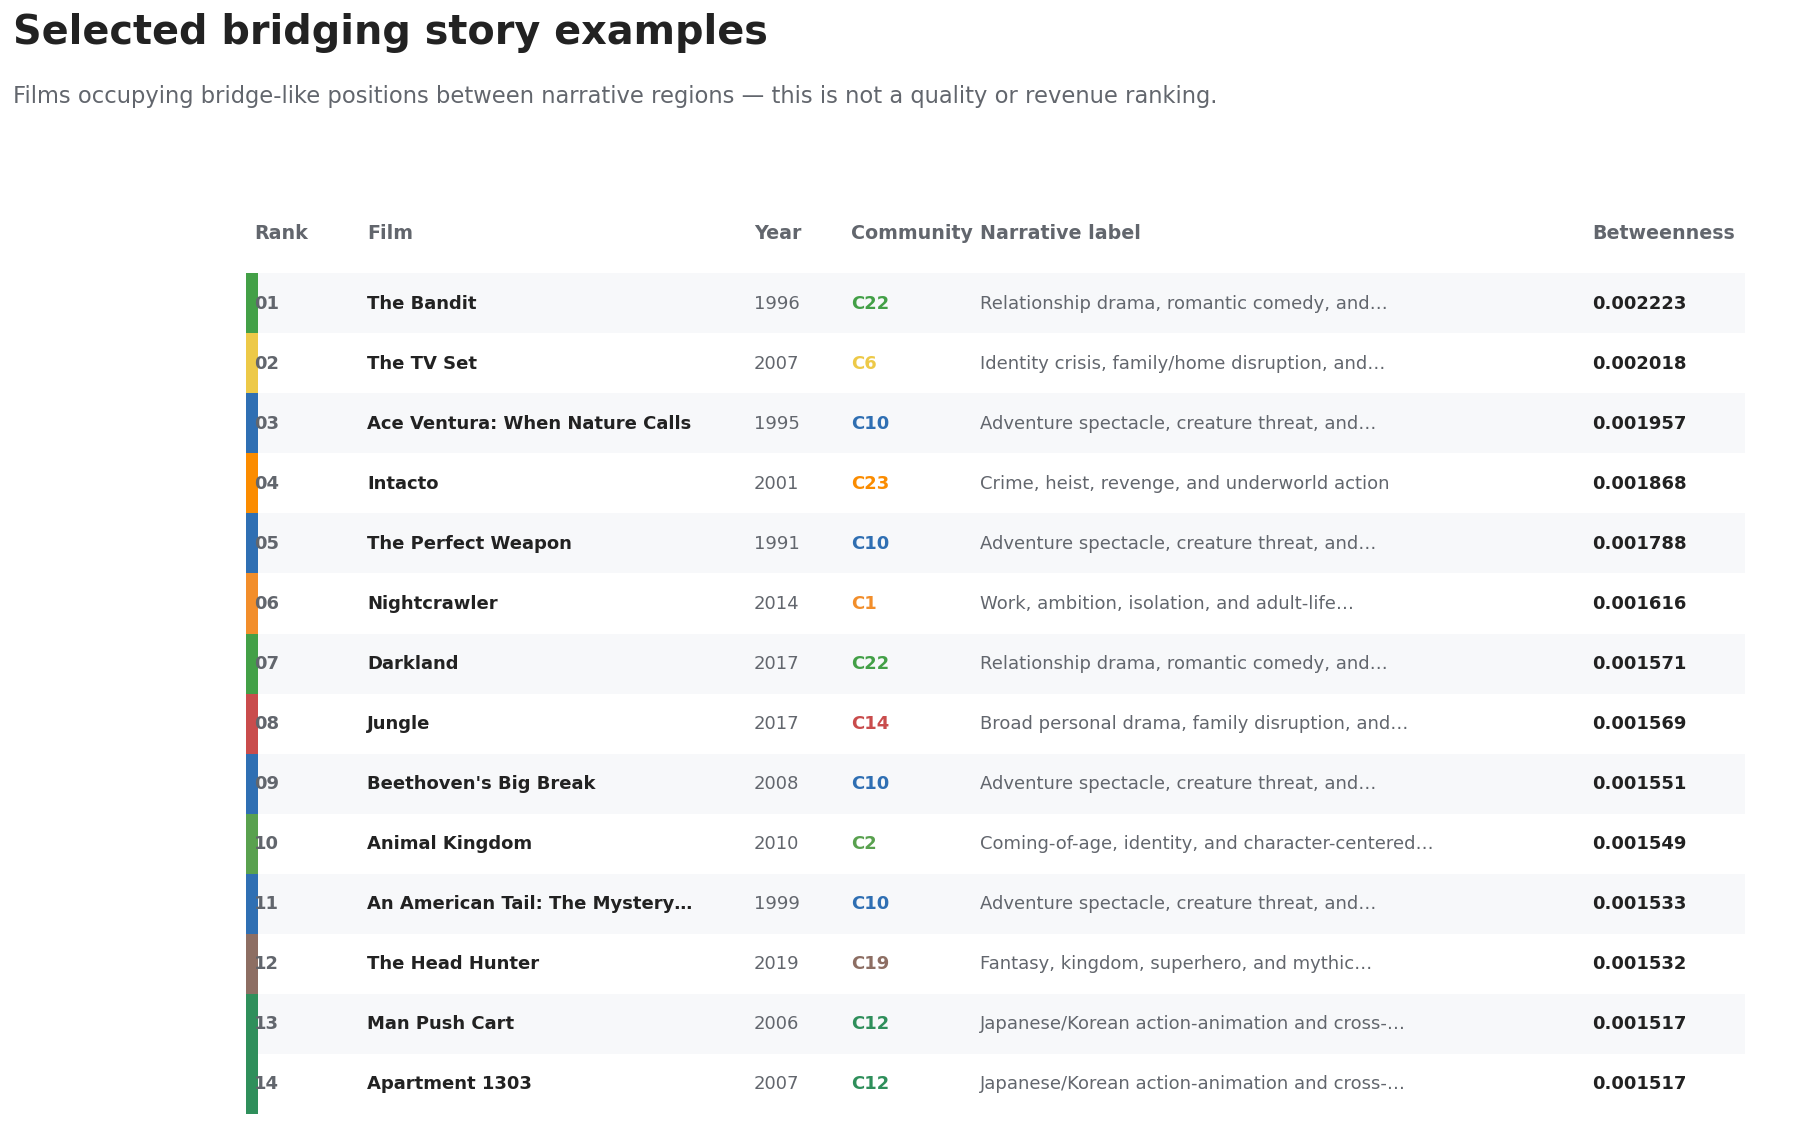


── Fig 5: Profile sheets ────────────────────────────────────────────
  ✓ Saved: 05_bridge_profile_C22_The_Bandit.png


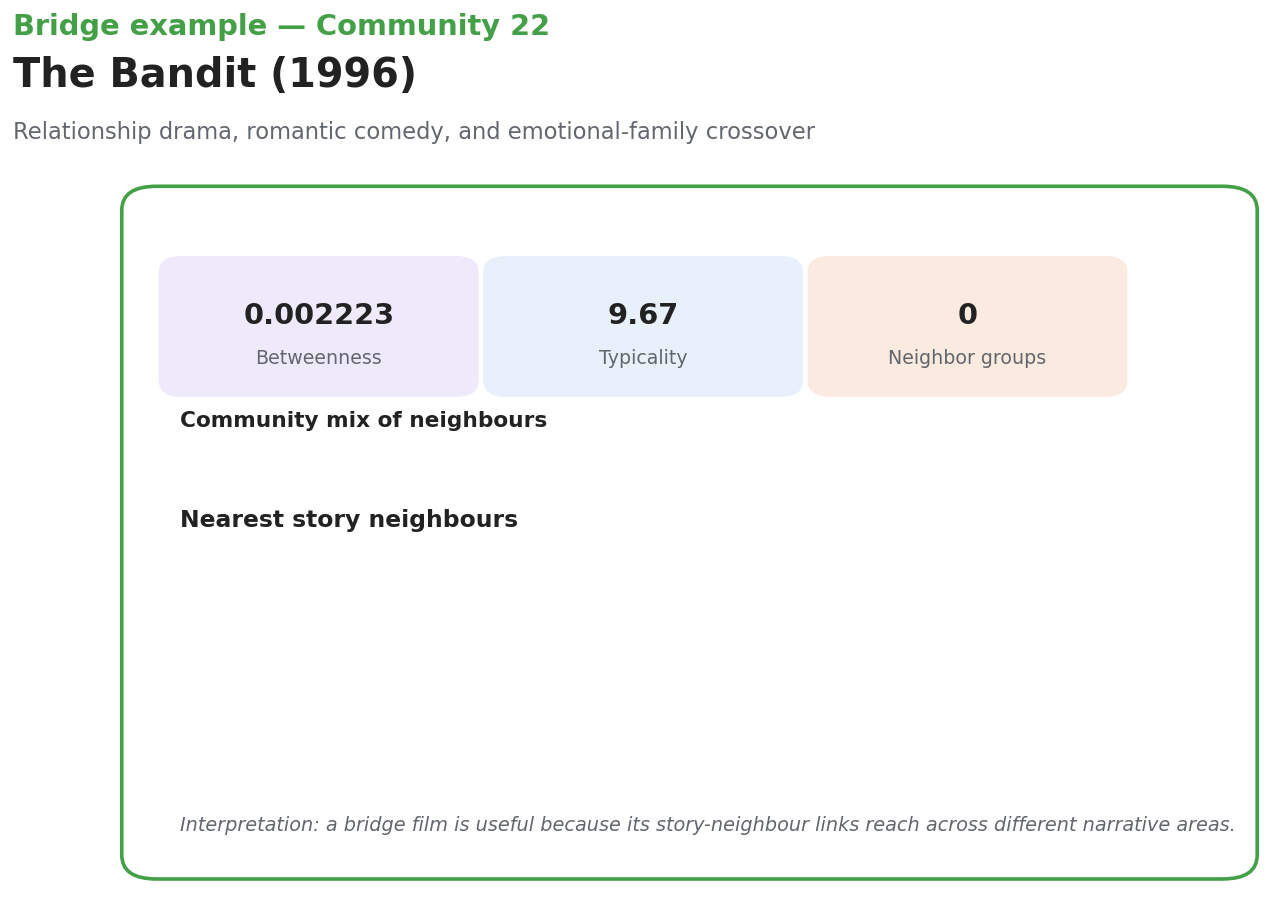

  ✓ Saved: 05_bridge_profile_C06_The_TV_Set.png


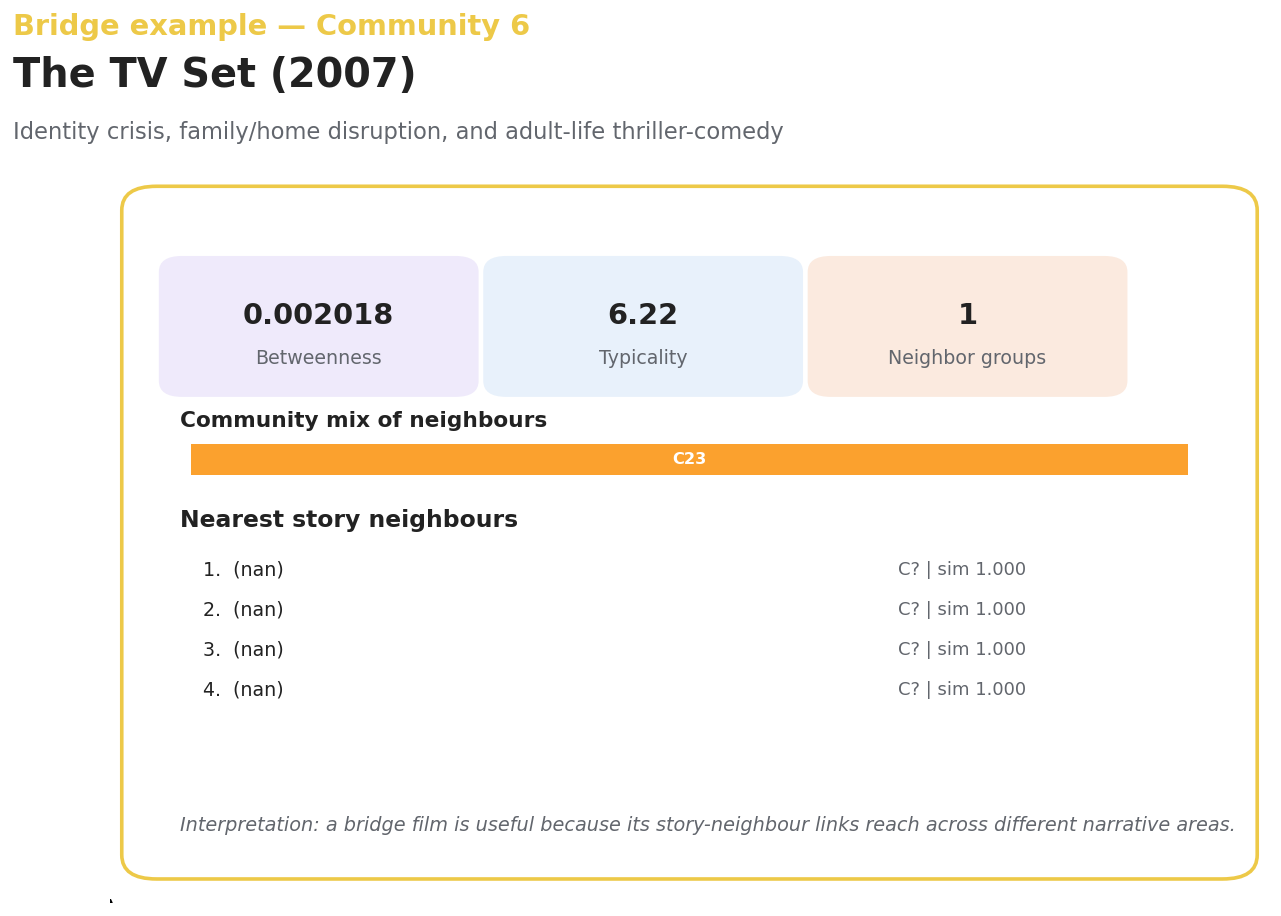

  ✓ Saved: 05_bridge_profile_C10_Ace_Ventura_When_Natur.png


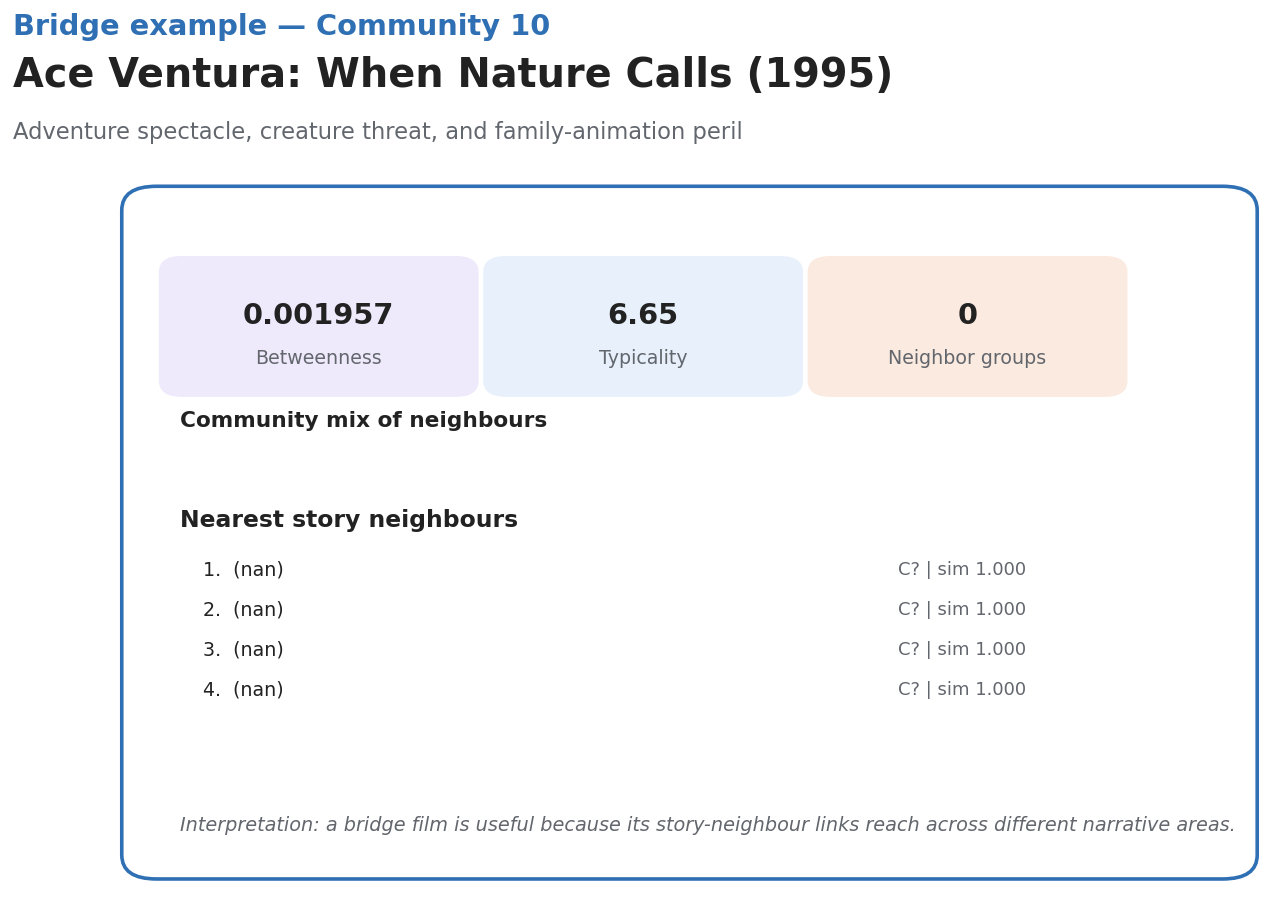

  ✓ Saved: 05_bridge_profile_C23_Intacto.png


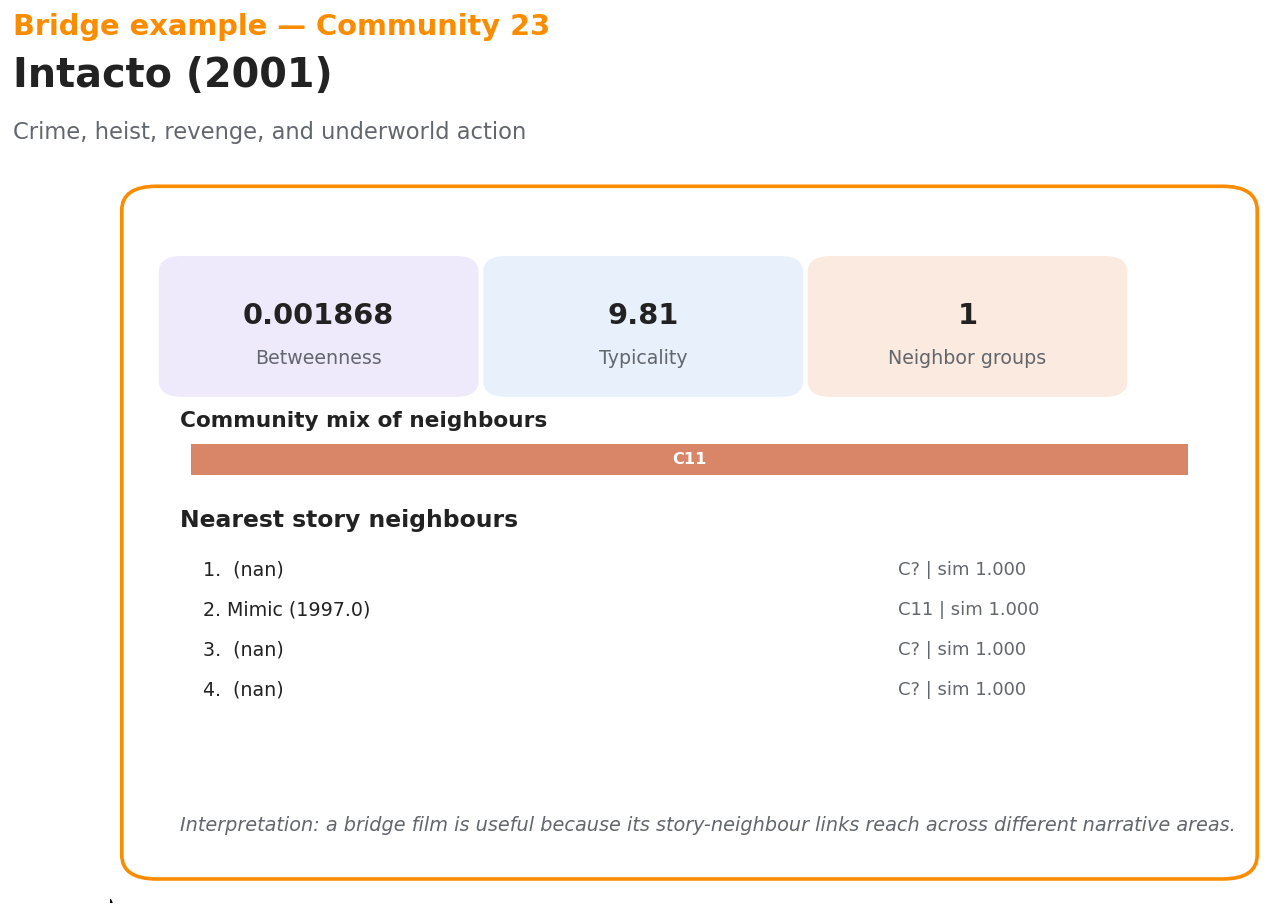

  ✓ Saved: 05_bridge_profile_C10_The_Perfect_Weapon.png


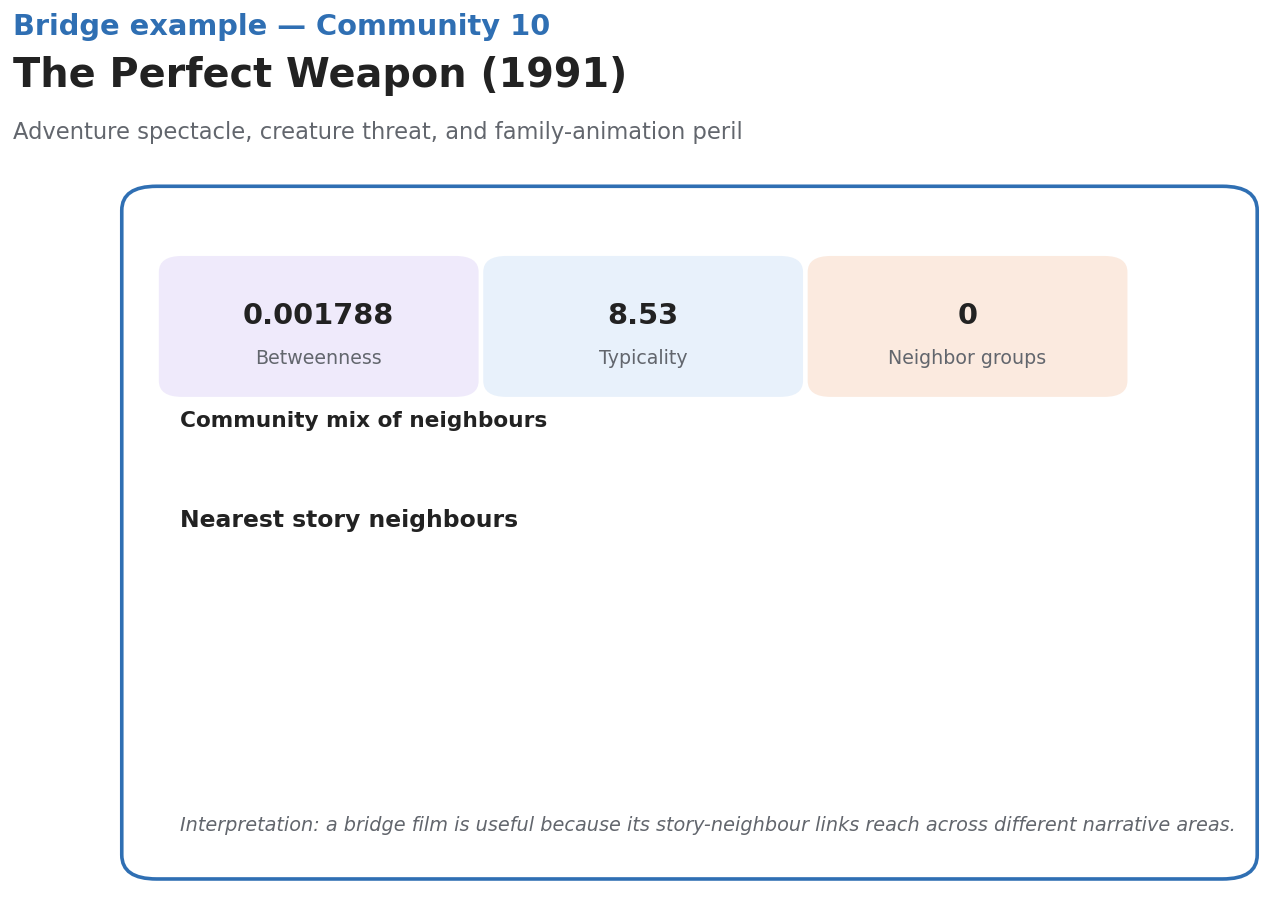

  ✓ Saved: 05_bridge_profile_C01_Nightcrawler.png


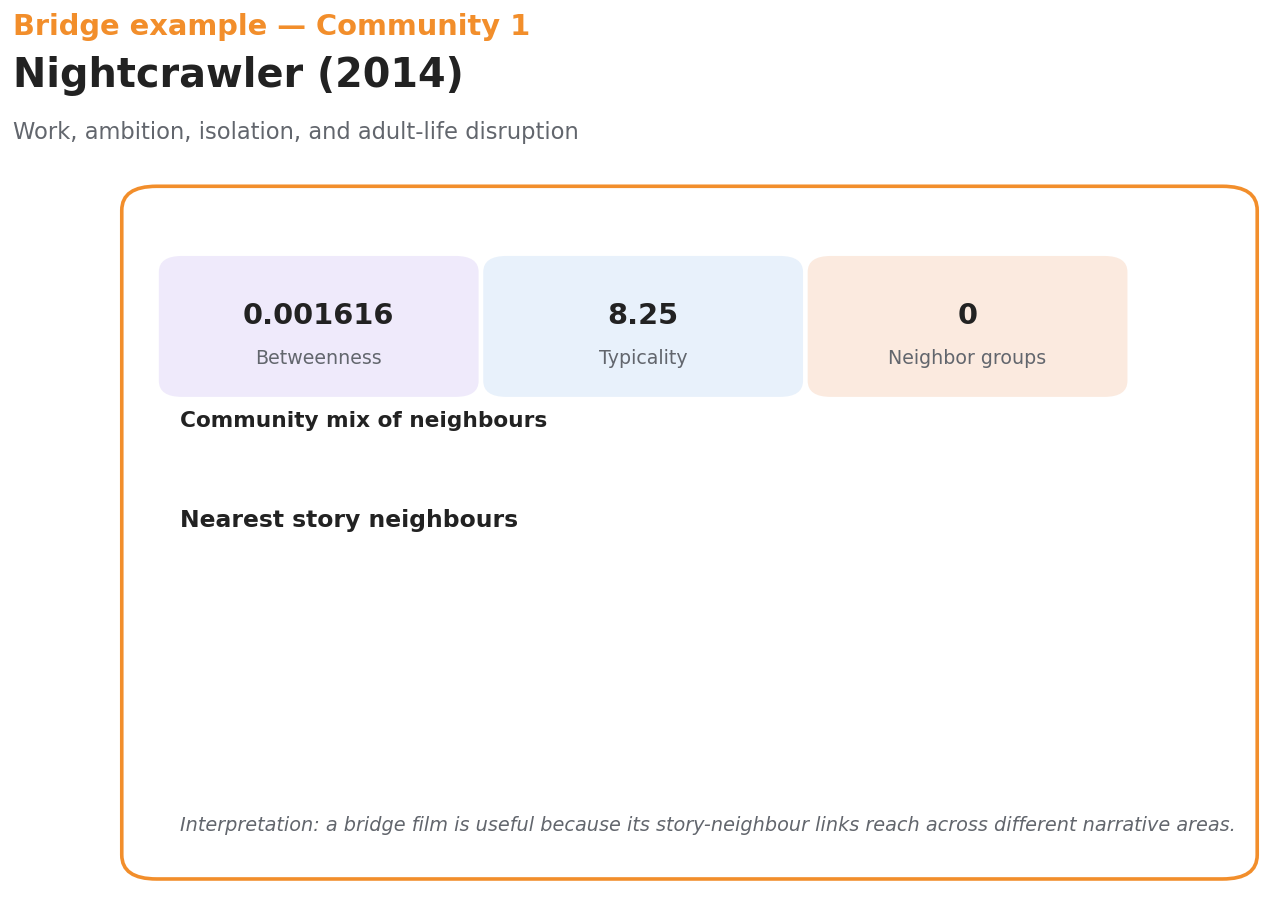


── Fig 6: Cross-community ego networks ──────────────────────────────
  Skipping The Bandit — no neighbours found.
  ✓ Saved table: 06_cross_community_neighborhood_C06_The_TV_Set.csv  [10 rows]
  ✓ Saved: 06_bridge_local_cross_community_C06_The_TV_Set.png


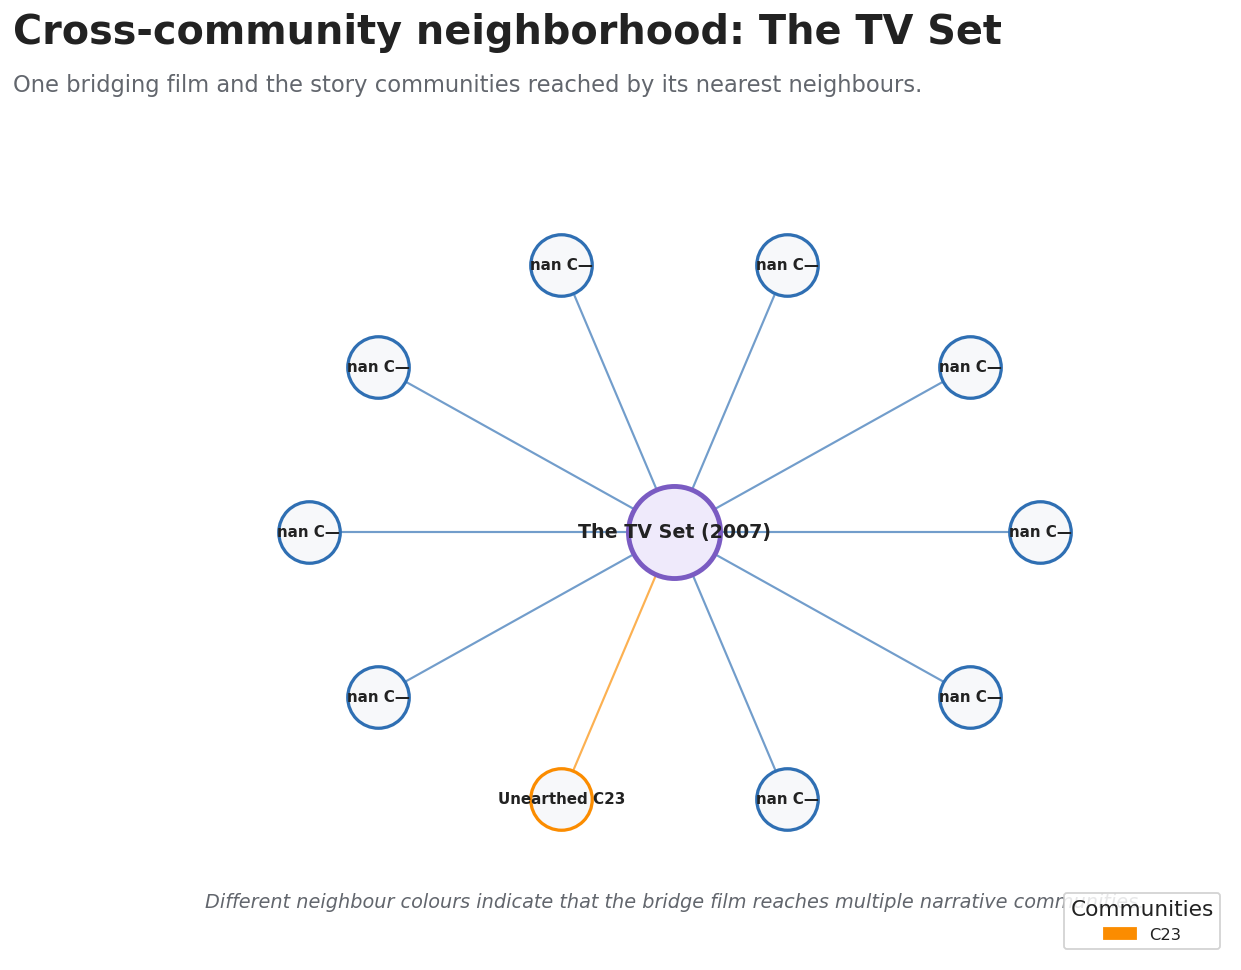

  ✓ Saved table: 06_cross_community_neighborhood_C10_Ace_Ventura_When_Natur.csv  [10 rows]
  ✓ Saved: 06_bridge_local_cross_community_C10_Ace_Ventura_When_Natur.png


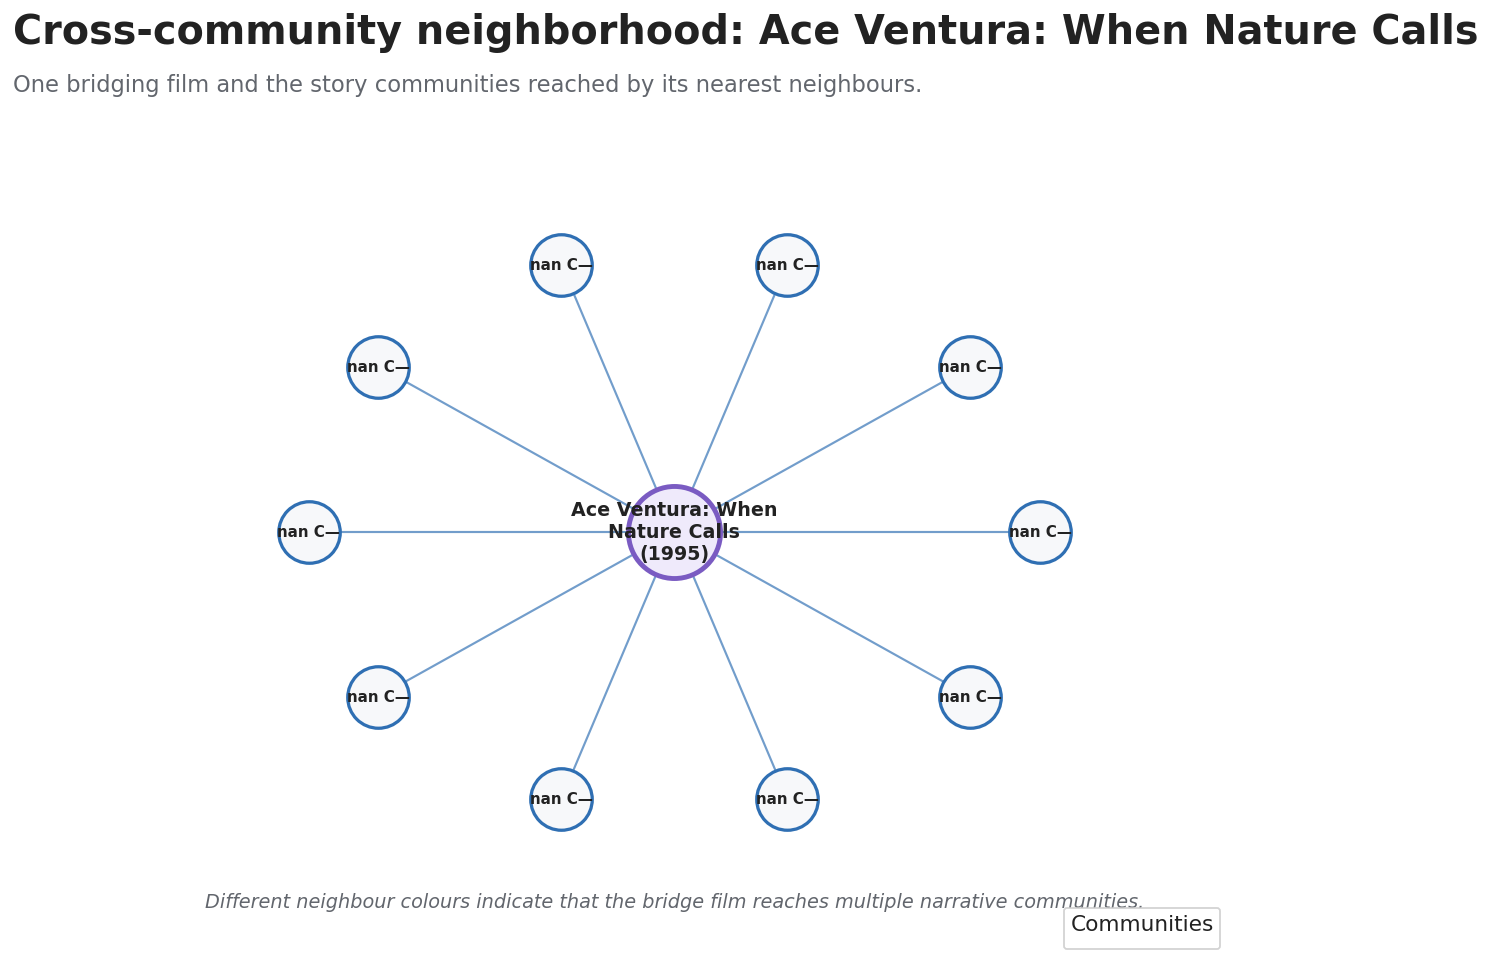

In [10]:
if nodes is not None and edges is not None:
    # ══════════════════════════════════════════════════════════════════════════════
    # 15. FIGURE 4 — Bridging films ranked table
    # ══════════════════════════════════════════════════════════════════════════════

    print("\n── Fig 4: Ranked table ──────────────────────────────────────────────")

    bridge_ranked = bridge_source.sort_values("bridge_score", ascending=False).head(CFG["ranked_table_n"]).copy()
    save_table(bridge_ranked,"04_bridging_films_ranked_table.csv")

    HEADERS  = ["Rank","Film","Year","Community","Narrative label","Betweenness"]
    COLS_W   = [0.07, 0.24, 0.06, 0.08, 0.38, 0.12]
    ROW_H    = 0.060

    fig, ax = plt.subplots(figsize=(16, 10))
    ax.axis("off")
    title_block(fig,
        "Selected bridging story examples",
        "Films occupying bridge-like positions between narrative regions — this is not a quality or revenue ranking.",
        x=0.04, y=0.965)

    xs = [0.04]
    for w in COLS_W[:-1]: xs.append(xs[-1]+w)
    start_y = 0.84

    for h,x0 in zip(HEADERS,xs):
        ax.text(x0, start_y+0.045, h, transform=ax.transAxes,
                fontsize=10.5, fontweight="bold", color=COL["muted"])

    for i,(_,r) in enumerate(bridge_ranked.iterrows(), 1):
        y     = start_y - (i-1)*ROW_H
        cid   = safe_int(r.get("community_id"), 0)
        color = community_color(cid)
        bg    = COL["panel"] if i%2==1 else "white"
        ax.add_patch(mpatches.Rectangle(
            (0.035, y-ROW_H+0.010), 0.93, ROW_H,
            transform=ax.transAxes, facecolor=bg, edgecolor="none"))
        ax.add_patch(mpatches.Rectangle(
            (0.035, y-ROW_H+0.010), 0.007, ROW_H,
            transform=ax.transAxes, facecolor=color, edgecolor="none"))

        ttl  = clean_title(r.get("title", r.get(title_col,"")))
        yr   = safe_int(r.get(year_col or "release_year",""), "")
        vals  = [f"{i:02d}", shorten(ttl,32), str(yr), f"C{cid}",
                 shorten(r.get("narrative_label",""),48), fmt_float(r.get("bridge_score",np.nan),6)]
        fws   = ["bold","bold","normal","bold","normal","bold"]
        fcs   = [COL["muted"],COL["ink"],COL["muted"],color,COL["muted"],COL["ink"]]

        for v,x0,fw,fc in zip(vals,xs,fws,fcs):
            ax.text(x0, y-0.020, v, transform=ax.transAxes,
                    fontsize=10.0, fontweight=fw, color=fc, va="center")

    save_fig(fig,"04_bridging_films_ranked_table.png"); plt.show()

    # ══════════════════════════════════════════════════════════════════════════════
    # 16. FIGURE 5 — Bridge profile sheets  (with community-mix bar)
    # ══════════════════════════════════════════════════════════════════════════════

    print("\n── Fig 5: Profile sheets ────────────────────────────────────────────")

    profiles = bridge_ranked.head(CFG["profile_n"]).copy()

    for _,r in profiles.iterrows():
        cid     = safe_int(r.get("community_id"), 0)
        color   = community_color(cid)
        node_id = str(r[node_id_col])
        title   = clean_title(r.get("title", r.get(title_col,"")))
        year    = safe_int(r.get(year_col or "release_year",""), "—")
        score   = r.get("bridge_score", np.nan)
        typs    = r.get("typicality_score", np.nan)
        neigh   = get_neighbors(node_id, top_n=CFG["profile_neighbors"])
        label   = str(r.get("narrative_label",""))

        # Community mix for bar chart
        if len(neigh) and "neighbor_community" in neigh.columns:
            comm_counts = neigh["neighbor_community"].value_counts()
            n_comm      = neigh["neighbor_community"].nunique()
            comm_text   = " · ".join([f"C{safe_int(k)} ({int(v)})" for k,v in comm_counts.head(4).items()])
        else:
            comm_counts = pd.Series(dtype=int)
            n_comm, comm_text = 0, "No neighbour data"

        fig, ax = plt.subplots(figsize=(11.5, 8.0))
        ax.axis("off")

        # Header
        fig.text(0.06, 0.945, f"Bridge example — Community {cid}",
                 fontsize=16, fontweight="bold", color=color, ha="left")
        fig.text(0.06, 0.895, f"{title} ({year})",
                 fontsize=22, fontweight="bold", color=COL["ink"], ha="left")
        fig.text(0.06, 0.845, wrap_text(label, 88),
                 fontsize=12.5, color=COL["muted"], ha="left")

        # Stat cards
        for x0, lbl, val, bg in [
            (0.06, "Betweenness",   fmt_float(score,6), COL["light_purple"]),
            (0.34, "Typicality",    fmt_float(typs,2),  COL["light_blue"]),
            (0.62, "Neighbor groups", str(n_comm),       COL["light_orange"]),
        ]:
            draw_card(ax, x0, 0.65, 0.24, 0.14, val, lbl, bg, fontsize_val=16)

        # Community-mix mini bar (NEW)
        ax.text(0.06, 0.595, "Community mix of neighbours",
                transform=ax.transAxes, fontsize=12, fontweight="bold")
        if len(comm_counts):
            total  = comm_counts.sum()
            x_bar  = 0.07
            bar_y  = 0.535
            bar_h  = 0.038
            for cid_n, cnt in comm_counts.head(6).items():
                bar_w = (cnt/total) * 0.86
                bc    = community_color(cid_n)
                ax.add_patch(mpatches.FancyArrow(0,0,0,0))  # dummy
                ax.add_patch(mpatches.Rectangle(
                    (x_bar, bar_y), bar_w, bar_h,
                    transform=ax.transAxes, facecolor=bc, edgecolor="none", alpha=0.82))
                if bar_w > 0.05:
                    ax.text(x_bar + bar_w/2, bar_y + bar_h/2,
                            f"C{safe_int(cid_n)}",
                            transform=ax.transAxes, ha="center", va="center",
                            fontsize=9, fontweight="bold", color="white")
                x_bar += bar_w

        # Nearest neighbours list
        ax.text(0.06, 0.47, "Nearest story neighbours",
                transform=ax.transAxes, fontsize=13, fontweight="bold")
        y_pos = 0.41
        if len(neigh):
            for i,(_,nr) in enumerate(neigh.head(4).iterrows(), 1):
                sim     = nr.get("edge_weight", np.nan)
                sim_txt = f"{sim:.3f}" if pd.notna(sim) else "n/a"
                nc      = safe_int(nr.get("neighbor_community",""), "?")
                ax.text(0.08, y_pos,
                        f"{i}. {shorten(nr['neighbor_title'],52)} ({nr.get('neighbor_year','—')})",
                        transform=ax.transAxes, fontsize=10.5, color=COL["ink"])
                ax.text(0.68, y_pos, f"C{nc} | sim {sim_txt}",
                        transform=ax.transAxes, fontsize=10.0, color=COL["muted"])
                y_pos -= 0.050

        ax.text(0.06, 0.09,
            "Interpretation: a bridge film is useful because its story-neighbour links "
            "reach across different narrative areas.",
            transform=ax.transAxes, fontsize=10.7, color=COL["muted"], style="italic")

        # Border
        ax.add_patch(FancyBboxPatch(
            (0.035,0.055), 0.93, 0.815,
            boxstyle="round,pad=0.025,rounding_size=0.03",
            facecolor="none", edgecolor=color, linewidth=2.0, transform=ax.transAxes))

        safe_ttl = re.sub(r"[^A-Za-z0-9]+","_",title)[:22]
        save_fig(fig, f"05_bridge_profile_C{cid:02d}_{safe_ttl}.png"); plt.show()

    # ══════════════════════════════════════════════════════════════════════════════
    # 17. FIGURE 6 — Local cross-community ego network
    # ══════════════════════════════════════════════════════════════════════════════

    print("\n── Fig 6: Cross-community ego networks ──────────────────────────────")

    for _,r in bridge_ranked.head(CFG["ego_n"]).iterrows():
        cid     = safe_int(r.get("community_id"), 0)
        color   = community_color(cid)
        node_id = str(r[node_id_col])
        title   = clean_title(r.get("title", r.get(title_col,"")))
        year    = safe_int(r.get(year_col or "release_year",""), "—")

        neigh   = get_neighbors(node_id, top_n=CFG["ego_neighbors"])
        if len(neigh) == 0:
            print(f"  Skipping {title} — no neighbours found."); continue

        safe_ttl = re.sub(r"[^A-Za-z0-9]+","_",title)[:22]
        save_table(neigh, f"06_cross_community_neighborhood_C{cid:02d}_{safe_ttl}.csv")

        fig, ax = plt.subplots(figsize=(11, 8.5))
        ax.axis("off"); ax.set_xlim(0,1); ax.set_ylim(0,1)
        title_block(fig,
            f"Cross-community neighborhood: {title}",
            "One bridging film and the story communities reached by its nearest neighbours.",
            x=0.05, y=0.965)

        center = (0.50, 0.50)
        ax.scatter(*center, s=2600, color=COL["light_purple"],
                   edgecolor=COL["purple"], linewidth=2.7, zorder=5)
        ax.text(*center, wrap_text(f"{title}\n({year})",18),
                ha="center", va="center", fontsize=10.5, fontweight="bold", zorder=6)

        n       = min(len(neigh), CFG["ego_neighbors"])
        angles  = np.linspace(0, 2*np.pi, n, endpoint=False)
        radius  = 0.33
        weights = neigh["edge_weight"].fillna(neigh["edge_weight"].median()).values[:n]
        wmin, wmax = np.nanmin(weights), np.nanmax(weights)

        for angle,(_,nr),w in zip(angles, neigh.head(n).iterrows(), weights):
            x = center[0] + radius*np.cos(angle)
            y = center[1] + radius*np.sin(angle)
            nc     = nr.get("neighbor_community", 0)
            ncolor = community_color(nc)
            lw     = 1.2 + 4.2*((w-wmin)/(wmax-wmin+1e-9))
            ax.plot([center[0],x],[center[1],y], color=ncolor, alpha=0.68, lw=lw, zorder=1)
            ax.scatter(x,y, s=1160, color=COL["panel"], edgecolor=ncolor, lw=1.8, zorder=3)
            ax.text(x,y,
                    wrap_text(f"{nr.get('neighbor_title','?')}\nC{safe_int(nc)}",18),
                    ha="center", va="center", fontsize=8.4, fontweight="bold", zorder=4)

        # Community colour legend
        unique_comms = neigh["neighbor_community"].dropna().unique()[:8]
        legend_patches = [
            mpatches.Patch(color=community_color(c), label=f"C{safe_int(c)}")
            for c in sorted(unique_comms)
        ]
        ax.legend(handles=legend_patches, loc="lower right", fontsize=9,
                  title="Communities", framealpha=0.85)

        ax.text(0.50, 0.058,
            "Different neighbour colours indicate that the bridge film reaches multiple narrative communities.",
            ha="center", fontsize=10.7, color=COL["muted"], style="italic")

        save_fig(fig, f"06_bridge_local_cross_community_C{cid:02d}_{safe_ttl}.png"); plt.show()

## Figures 7 - 9


── Fig 7a: Bridge vs typicality scatter ─────────────────────────────
  ✓ Saved table: 07a_bridge_vs_centrality_data.csv  [50 rows]
  ✓ Saved: 07a_bridge_vs_centrality_selected_map.png


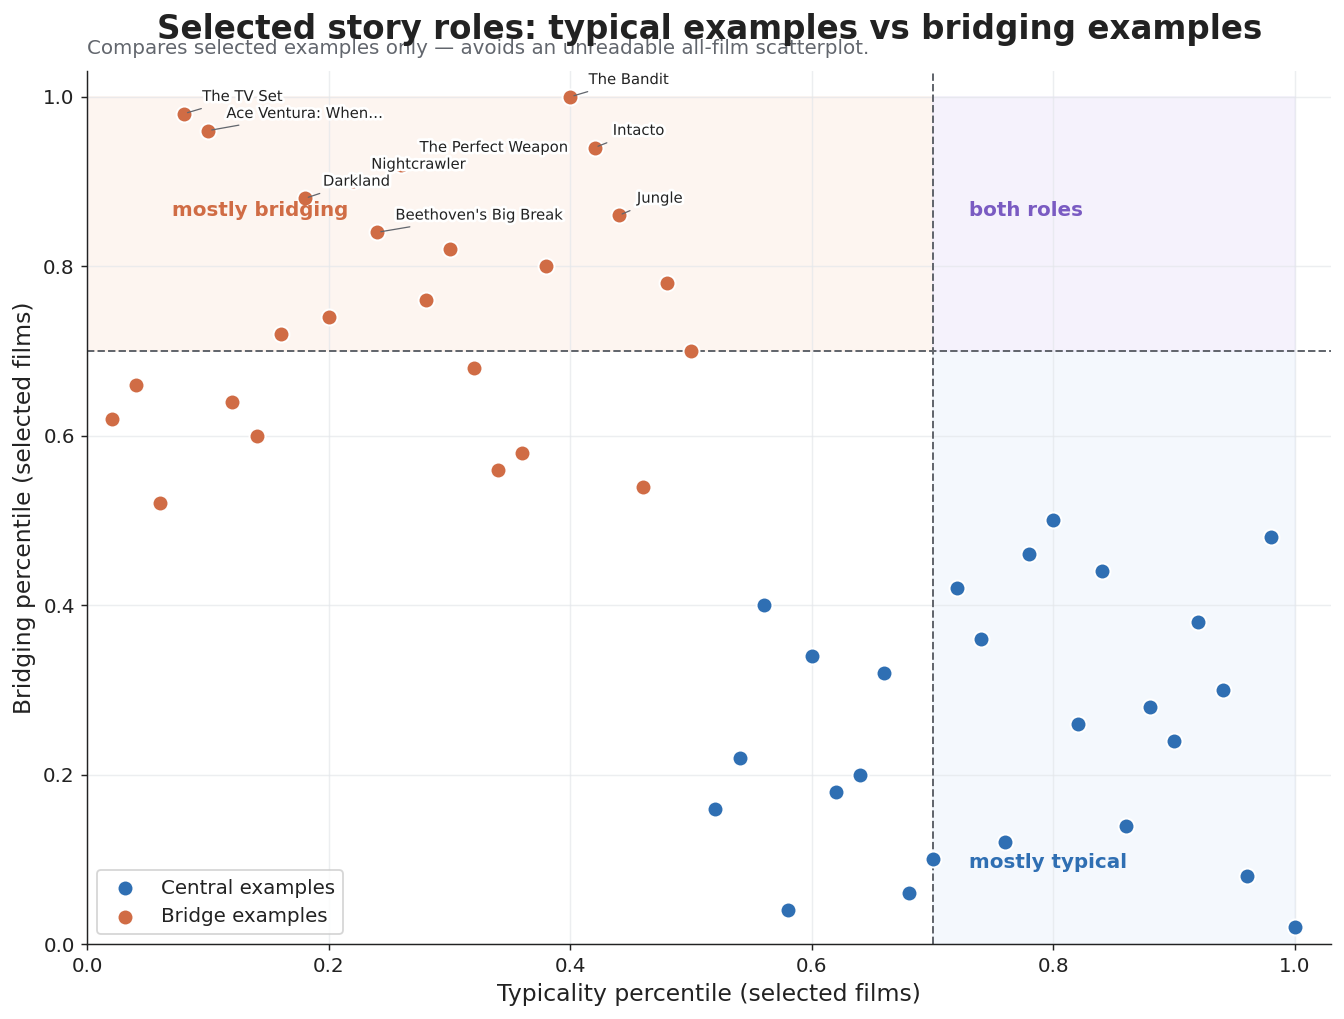


── Fig 7b: Community-reach heatmap (NEW) ────────────────────────────
  ✓ Saved table: 07b_community_reach_heatmap_data.csv  [12 rows]
  ✓ Saved: 07b_community_reach_heatmap.png


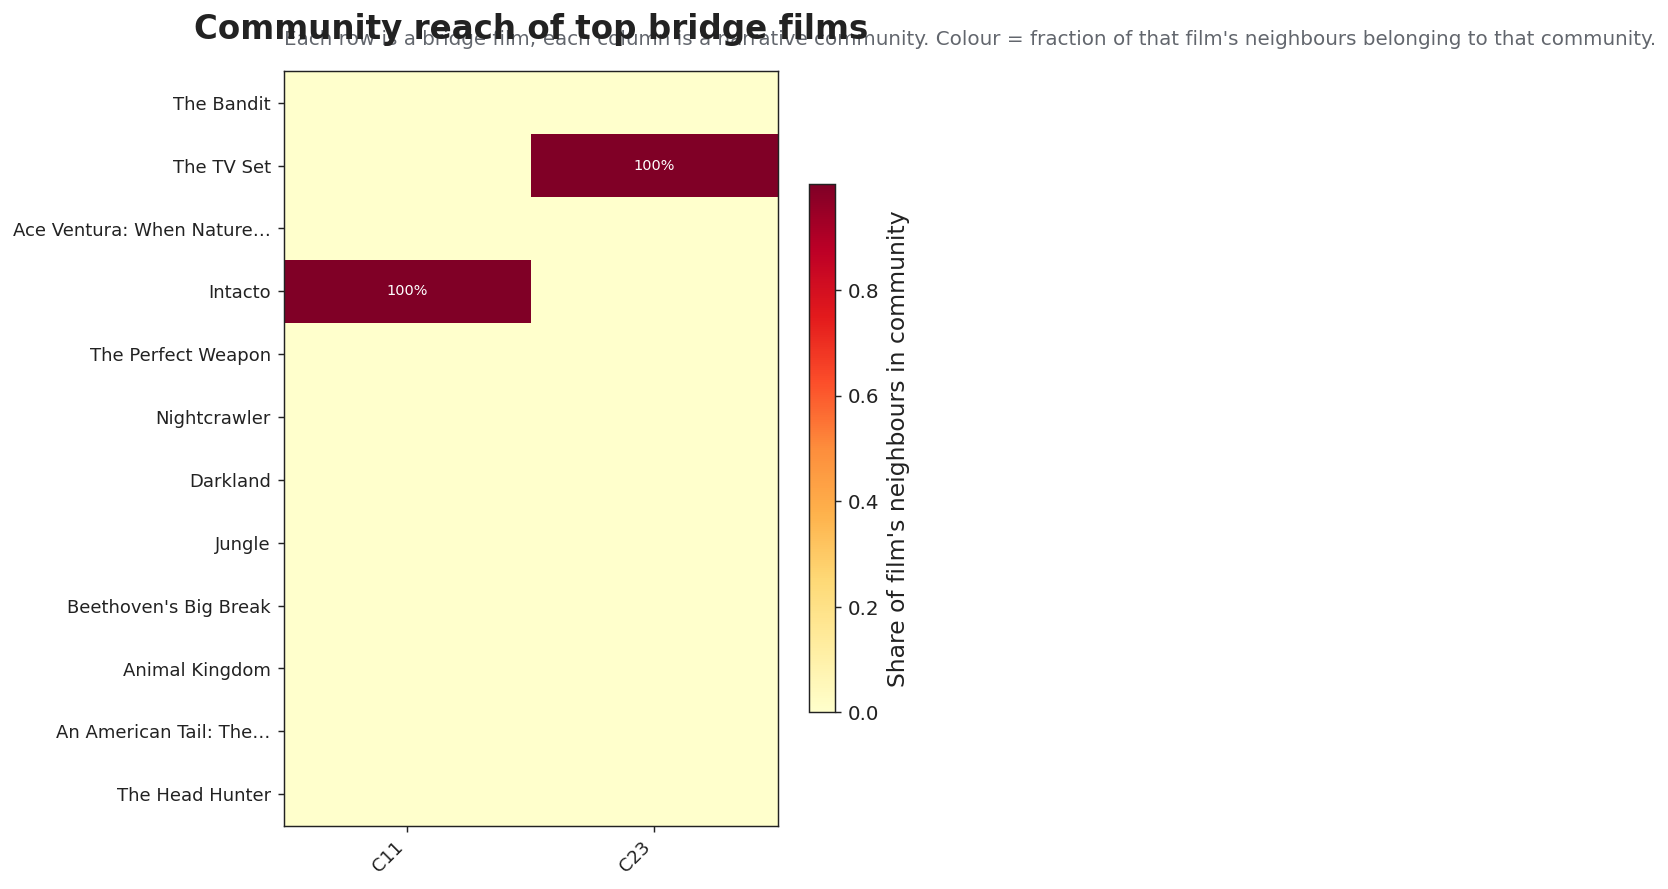


── Fig 8: Interpretation summary ────────────────────────────────────
  ✓ Saved: 08_bridging_interpretation_summary.png


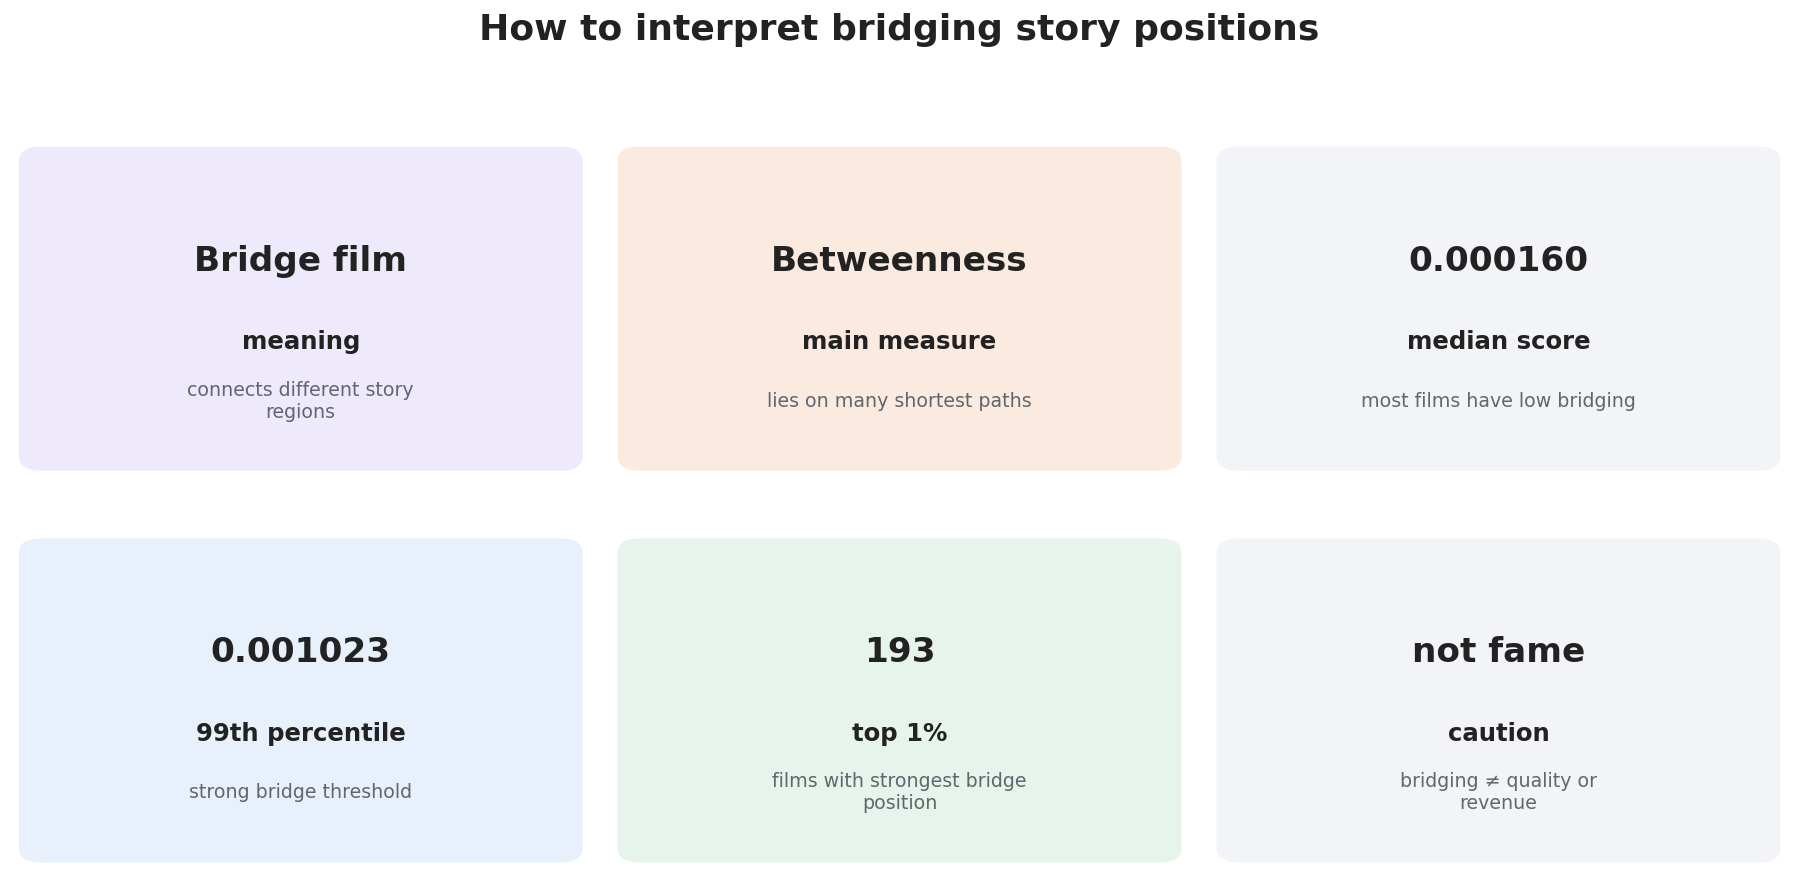


── Fig 9: Bridge role taxonomy (NEW) ────────────────────────────────
  ✓ Saved table: 09_bridge_role_taxonomy.csv  [60 rows]
  ✓ Saved: 09_bridge_role_taxonomy.png


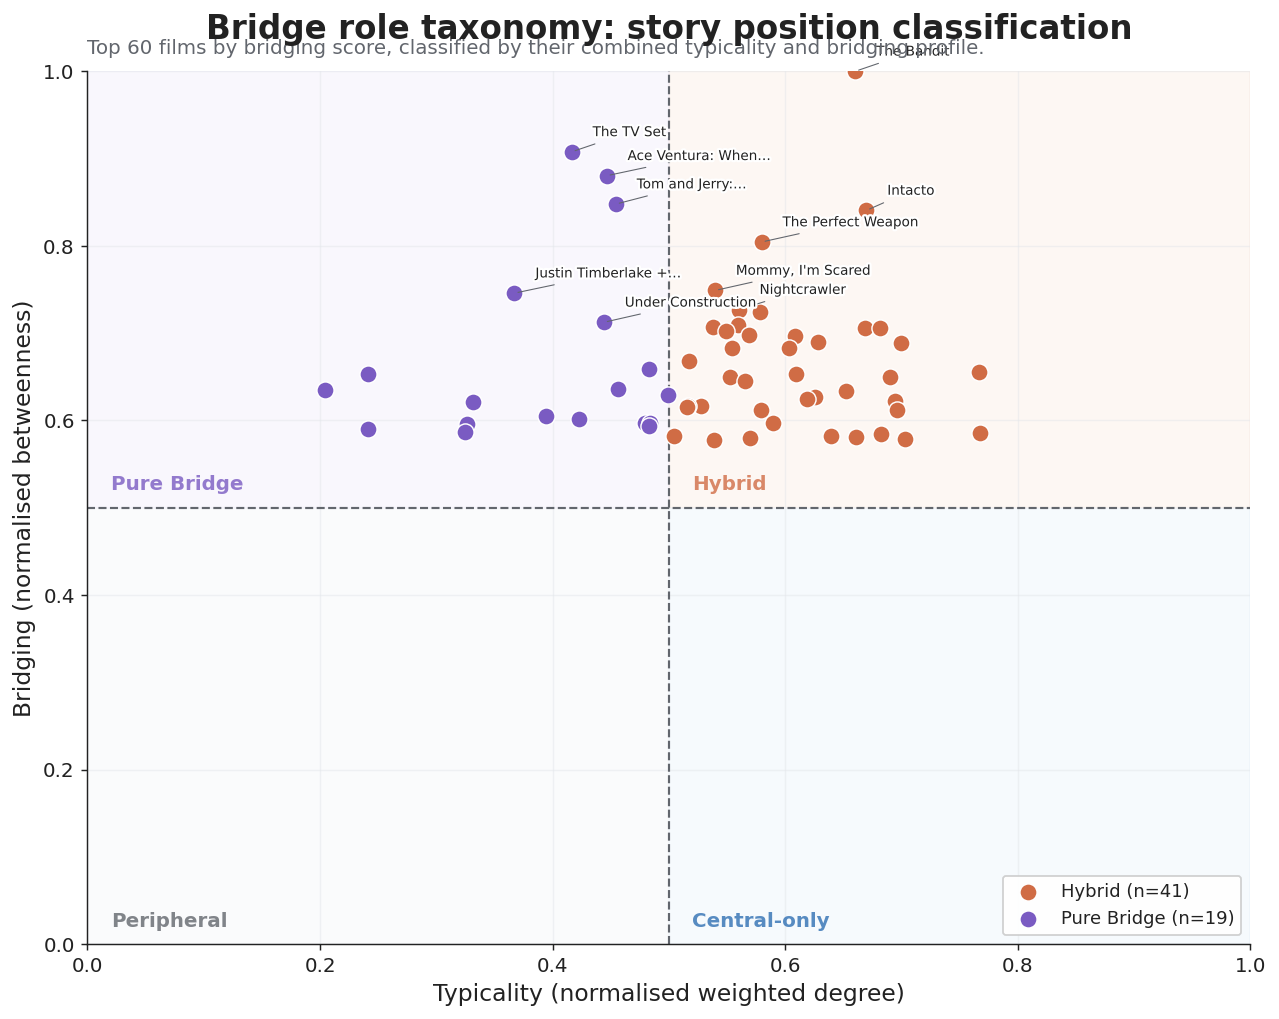

  ✓ Saved table: 09_bridge_role_taxonomy_summary.csv  [2 rows]
       role  count
     Hybrid     41
Pure Bridge     19


In [12]:
if nodes is not None and edges is not None:
    # ══════════════════════════════════════════════════════════════════════════════
    # 18. FIGURE 7a — Bridge vs. typicality scatter
    # ══════════════════════════════════════════════════════════════════════════════

    print("\n── Fig 7a: Bridge vs typicality scatter ─────────────────────────────")

    sel_bridge = bridge_source.sort_values("bridge_score", ascending=False).head(CFG["scatter_top_n"]).copy()
    sel_bridge["role"] = "Bridge examples"

    # Typicality source
    typ_source = None
    for df in [top_visible_central, top_wdeg_visible]:
        if df is not None and len(df):
            typ_source = df.copy(); break

    if typ_source is None:
        typ_source = bridge_nodes.sort_values("typicality_score", ascending=False).copy()
        typ_source["typicality_score"] = typ_source["typicality_score"]

    if node_id_col not in typ_source.columns:
        t_lower = typ_source.get("title", typ_source.iloc[:,0]).astype(str).str.strip().str.lower()

        # Ensure the id_map has a unique index to avoid InvalidIndexError
        # This assumes that if there are duplicate titles, keeping the first node_id is acceptable.
        temp_bridge_nodes = bridge_nodes[[title_col, node_id_col]].copy()
        temp_bridge_nodes[title_col] = temp_bridge_nodes[title_col].astype(str).str.strip().str.lower()
        temp_bridge_nodes = temp_bridge_nodes.drop_duplicates(subset=[title_col])

        id_map = temp_bridge_nodes.set_index(title_col)[node_id_col]
        typ_source[node_id_col] = t_lower.map(id_map)
    typ_source = typ_source.dropna(subset=[node_id_col]).copy()
    typ_source[node_id_col] = typ_source[node_id_col].astype(str)

    # Merge bridge scores into typ_source
    typ_source = typ_source.merge(
        bridge_nodes[[node_id_col,"bridge_score","typicality_score"]],
        on=node_id_col, how="left", suffixes=("","_node"))
    if "typicality_score" not in typ_source.columns:
        typ_source["typicality_score"] = typ_source.get("typicality_score_node",np.nan)

    sel_central = typ_source.sort_values("typicality_score",ascending=False).head(CFG["scatter_top_n"]).copy()
    sel_central["role"] = "Central examples"

    common_cols = list((set(sel_bridge.columns) & set(sel_central.columns)) | {"role"})
    plot = pd.concat([sel_bridge[common_cols], sel_central[common_cols]],
                     ignore_index=True).drop_duplicates(subset=[node_id_col,"role"])

    for col in ["bridge_score","typicality_score"]:
        if col not in plot.columns: plot[col] = np.nan

    plot["bridge_pct"]    = plot["bridge_score"].rank(pct=True)
    plot["typicality_pct"]= plot["typicality_score"].rank(pct=True)
    save_table(plot,"07a_bridge_vs_centrality_data.csv")

    fig, ax = plt.subplots(figsize=(10.5, 8))
    ax.add_patch(mpatches.Rectangle((0.70,0.00),0.30,0.70, color=COL["light_blue"],  alpha=0.45, zorder=0))
    ax.add_patch(mpatches.Rectangle((0.00,0.70),0.70,0.30, color=COL["light_orange"],alpha=0.45, zorder=0))
    ax.add_patch(mpatches.Rectangle((0.70,0.70),0.30,0.30, color=COL["light_purple"],alpha=0.60, zorder=0))
    ax.axvline(0.70, color=COL["muted"], ls="--", lw=1.1)
    ax.axhline(0.70, color=COL["muted"], ls="--", lw=1.1)

    for role,col in [("Central examples",COL["blue"]),("Bridge examples",COL["orange"])]:
        sub = plot[plot["role"]==role]
        ax.scatter(sub["typicality_pct"], sub["bridge_pct"],
                   s=78, color=col, edgecolor="white", lw=1.1, label=role, zorder=3)

    # Label top bridge films
    for _,rr in plot.sort_values("bridge_pct",ascending=False).head(9).iterrows():
        ttl = clean_title(rr.get("title", rr.get(title_col,"")))
        ax.annotate(shorten(ttl,22),
            xy=(rr["typicality_pct"], rr["bridge_pct"]),
            xytext=(rr["typicality_pct"]+0.015, rr["bridge_pct"]+0.015),
            fontsize=8.2,
            arrowprops=dict(arrowstyle="-", color=COL["muted"], lw=0.7),
            path_effects=[pe.withStroke(linewidth=3, foreground="white")])

    ax.text(0.73, 0.09, "mostly typical",  fontsize=11, fontweight="bold", color=COL["blue"])
    ax.text(0.07, 0.86, "mostly bridging", fontsize=11, fontweight="bold", color=COL["orange"])
    ax.text(0.73, 0.86, "both roles",      fontsize=11, fontweight="bold", color=COL["purple"])
    ax.set_xlim(0,1.03); ax.set_ylim(0,1.03)
    ax.set_xlabel("Typicality percentile (selected films)")
    ax.set_ylabel("Bridging percentile (selected films)")
    ax.set_title("Selected story roles: typical examples vs bridging examples", pad=18)
    ax.text(0,1.02,
        "Compares selected examples only — avoids an unreadable all-film scatterplot.",
        transform=ax.transAxes, fontsize=11, color=COL["muted"])
    ax.spines[["top","right"]].set_visible(False)
    ax.grid(color=COL["grid"], alpha=0.7)
    ax.legend(loc="lower left")
    plt.tight_layout()
    save_fig(fig,"07a_bridge_vs_centrality_selected_map.png"); plt.show()

    # ══════════════════════════════════════════════════════════════════════════════
    # 19. FIGURE 7b — NEW: Community-reach heatmap
    # Shows which bridge films span which communities (brokerage matrix)
    # ══════════════════════════════════════════════════════════════════════════════

    print("\n── Fig 7b: Community-reach heatmap (NEW) ────────────────────────────")

    top_bridges  = bridge_ranked.head(CFG["heatmap_top_bridges"]).copy()
    bridge_titles = []
    reach_matrix  = []

    for _,r in top_bridges.iterrows():
        nid   = str(r[node_id_col])
        ttl   = shorten(clean_title(r.get("title", r.get(title_col,""))), 28)
        neigh = get_neighbors(nid, top_n=CFG["profile_neighbors"])
        bridge_titles.append(ttl)
        if len(neigh) and "neighbor_community" in neigh.columns:
            counts = neigh["neighbor_community"].value_counts().to_dict()
        else:
            counts = {}
        reach_matrix.append(counts)

    # All communities that appear
    all_comms = sorted(set(c for row in reach_matrix for c in row.keys()))
    matrix_df = pd.DataFrame(reach_matrix, index=bridge_titles, columns=all_comms).fillna(0)
    matrix_df.columns = [f"C{safe_int(c)}" for c in matrix_df.columns]

    # Normalise per row so colour = share of that film's neighbourhood in each community
    matrix_norm = matrix_df.div(matrix_df.sum(axis=1)+1e-9, axis=0)
    save_table(matrix_df.reset_index().rename(columns={"index":"film"}),
               "07b_community_reach_heatmap_data.csv")

    if len(matrix_norm.columns) >= 2:
        fig, ax = plt.subplots(figsize=(max(10, len(matrix_norm.columns)*0.9), 7))
        cmap = plt.cm.YlOrPd if hasattr(plt.cm,"YlOrPd") else plt.cm.YlOrRd
        im   = ax.imshow(matrix_norm.values, aspect="auto", cmap=cmap, vmin=0, vmax=matrix_norm.values.max())

        ax.set_xticks(range(len(matrix_norm.columns)))
        ax.set_xticklabels(matrix_norm.columns, rotation=45, ha="right", fontsize=10)
        ax.set_yticks(range(len(bridge_titles)))
        ax.set_yticklabels(bridge_titles, fontsize=10)

        # Annotate cells
        for i in range(len(bridge_titles)):
            for j in range(len(matrix_norm.columns)):
                val = matrix_norm.values[i,j]
                if val > 0.05:
                    ax.text(j, i, f"{val:.0%}", ha="center", va="center",
                            fontsize=8, color="white" if val > 0.45 else COL["ink"])

        plt.colorbar(im, ax=ax, label="Share of film's neighbours in community", shrink=0.7)
        ax.set_title("Community reach of top bridge films", pad=18, fontsize=18, fontweight="bold")
        ax.text(0, 1.035,
            "Each row is a bridge film; each column is a narrative community. "
            "Colour = fraction of that film's neighbours belonging to that community.",
            transform=ax.transAxes, fontsize=11, color=COL["muted"])
        plt.tight_layout()
        save_fig(fig,"07b_community_reach_heatmap.png"); plt.show()
    else:
        print("  ⚠  Too few communities for heatmap.")

    # ══════════════════════════════════════════════════════════════════════════════
    # 20. FIGURE 8 — Interpretation summary cards
    # ══════════════════════════════════════════════════════════════════════════════

    print("\n── Fig 8: Interpretation summary ────────────────────────────────────")

    x = bridge_nodes["bridge_score"].dropna()
    top_1_pct  = int((bridge_nodes["bridge_percentile"] >= 0.99).sum()) if x.notna().any() else 0
    med_score  = x.median() if x.notna().any() else np.nan
    p99_score  = x.quantile(.99) if x.notna().any() else np.nan

    cards = [
        ("Bridge film",          "meaning",          "connects different story regions",          COL["light_purple"]),
        ("Betweenness",          "main measure",     "lies on many shortest paths",               COL["light_orange"]),
        (fmt_float(med_score,6), "median score",     "most films have low bridging",              COL["light_gray"]),
        (fmt_float(p99_score,6), "99th percentile",  "strong bridge threshold",                   COL["light_blue"]),
        (fmt_int(top_1_pct),     "top 1%",           "films with strongest bridge position",      COL["light_green"]),
        ("not fame",             "caution",          "bridging ≠ quality or revenue",             COL["light_gray"]),
    ]

    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for ax,(val,title,sub,bg) in zip(axes.ravel(), cards):
        ax.axis("off")
        ax.add_patch(FancyBboxPatch(
            (0.04,0.08), 0.92, 0.82,
            boxstyle="round,pad=0.03,rounding_size=0.04",
            facecolor=bg, edgecolor="none"))
        ax.text(0.5,0.62,val,  ha="center", va="center", fontsize=19, fontweight="bold")
        ax.text(0.5,0.40,title,ha="center", va="center", fontsize=13.5, fontweight="bold")
        ax.text(0.5,0.24,wrap_text(sub,28),
                ha="center", va="center", fontsize=10.5, color=COL["muted"])

    fig.suptitle("How to interpret bridging story positions",
                 fontsize=20, fontweight="bold", y=0.98)
    plt.tight_layout(rect=[0,0,1,0.95])
    save_fig(fig,"08_bridging_interpretation_summary.png"); plt.show()

    # ══════════════════════════════════════════════════════════════════════════════
    # 21. FIGURE 9 — NEW: Bridge role taxonomy
    # Classifies films into: Pure Bridge / Hybrid / Peripheral / Central-only
    # ══════════════════════════════════════════════════════════════════════════════

    print("\n── Fig 9: Bridge role taxonomy (NEW) ────────────────────────────────")

    tax = bridge_nodes[[node_id_col, title_col,
                         "bridge_score_norm","typicality_score_norm"]].dropna().copy()
    tax = tax.nlargest(CFG["taxonomy_top_n"], "bridge_score_norm")

    HIGH_B = 0.50   # threshold for "high bridge"  (within this top-N subset)
    HIGH_T = 0.50   # threshold for "high typicality"

    def classify(row):
        b = row["bridge_score_norm"]
        t = row["typicality_score_norm"]
        if b >= HIGH_B and t >= HIGH_T: return "Hybrid"
        if b >= HIGH_B and t <  HIGH_T: return "Pure Bridge"
        if b <  HIGH_B and t >= HIGH_T: return "Central-only"
        return "Peripheral"

    tax["role"] = tax.apply(classify, axis=1)
    role_colors = {
        "Pure Bridge":   COL["purple"],
        "Hybrid":        COL["orange"],
        "Central-only":  COL["blue"],
        "Peripheral":    COL["muted"],
    }
    save_table(tax, "09_bridge_role_taxonomy.csv")

    fig, ax = plt.subplots(figsize=(10, 8))

    # Background quadrants
    ax.add_patch(mpatches.Rectangle((HIGH_T,HIGH_B),1-HIGH_T,1-HIGH_B,
        color=COL["light_orange"], alpha=0.35, zorder=0))
    ax.add_patch(mpatches.Rectangle((0,HIGH_B),HIGH_T,1-HIGH_B,
        color=COL["light_purple"], alpha=0.35, zorder=0))
    ax.add_patch(mpatches.Rectangle((HIGH_T,0),1-HIGH_T,HIGH_B,
        color=COL["light_blue"],   alpha=0.35, zorder=0))
    ax.add_patch(mpatches.Rectangle((0,0),HIGH_T,HIGH_B,
        color=COL["light_gray"],   alpha=0.35, zorder=0))

    ax.axvline(HIGH_T, color=COL["muted"], ls="--", lw=1.2)
    ax.axhline(HIGH_B, color=COL["muted"], ls="--", lw=1.2)

    for role, group in tax.groupby("role"):
        col = role_colors.get(role, COL["muted"])
        ax.scatter(group["typicality_score_norm"], group["bridge_score_norm"],
                   s=90, color=col, edgecolor="white", lw=0.8,
                   label=f"{role} (n={len(group)})", zorder=3)

    # Label top-5 of each quadrant
    for role, group in tax.groupby("role"):
        top5 = group.nlargest(5,"bridge_score_norm") if role in ("Pure Bridge","Hybrid") \
               else group.nlargest(3,"typicality_score_norm")
        for _,rr in top5.iterrows():
            ttl = clean_title(rr[title_col])
            ax.annotate(shorten(ttl,20),
                xy=(rr["typicality_score_norm"], rr["bridge_score_norm"]),
                xytext=(rr["typicality_score_norm"]+0.018, rr["bridge_score_norm"]+0.018),
                fontsize=7.5,
                arrowprops=dict(arrowstyle="-", color=COL["muted"], lw=0.6),
                path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

    # Quadrant labels
    ax.text(HIGH_T+0.02, HIGH_B+0.02, "Hybrid", fontsize=11, fontweight="bold", color=COL["orange"], alpha=0.8)
    ax.text(0.02,         HIGH_B+0.02, "Pure Bridge", fontsize=11, fontweight="bold", color=COL["purple"], alpha=0.8)
    ax.text(HIGH_T+0.02, 0.02,         "Central-only", fontsize=11, fontweight="bold", color=COL["blue"],  alpha=0.8)
    ax.text(0.02,         0.02,         "Peripheral", fontsize=11, fontweight="bold", color=COL["muted"], alpha=0.8)

    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_xlabel("Typicality (normalised weighted degree)")
    ax.set_ylabel("Bridging (normalised betweenness)")
    ax.set_title("Bridge role taxonomy: story position classification", pad=18)
    ax.text(0,1.02,
        f"Top {CFG['taxonomy_top_n']} films by bridging score, classified by their combined typicality and bridging profile.",
        transform=ax.transAxes, fontsize=11, color=COL["muted"])
    ax.legend(loc="lower right", fontsize=10, framealpha=0.9)
    ax.spines[["top","right"]].set_visible(False)
    ax.grid(color=COL["grid"], alpha=0.5)
    plt.tight_layout()
    save_fig(fig,"09_bridge_role_taxonomy.png"); plt.show()

    role_summary = tax["role"].value_counts().reset_index()
    role_summary.columns = ["role","count"]
    save_table(role_summary,"09_bridge_role_taxonomy_summary.csv")
    print(role_summary.to_string(index=False))

## Interpretation Note & Output Manifest

In [13]:
if nodes is not None and edges is not None:
    # ══════════════════════════════════════════════════════════════════════════════
    # 22. INTERPRETATION NOTE
    # ══════════════════════════════════════════════════════════════════════════════

    note = f"""
    Brick 6 — Bridging story positions interpretation note

    Main message:
    A bridging film is a film that lies between different narrative regions in the
    plot-similarity network. In this thesis, bridging is interpreted as narrative
    brokerage or cross-community story position, not as fame, quality, revenue,
    or star power.

    Measure: betweenness centrality (column: {bet_col or 'N/A'}).
    Normalised score range: 0.0 – 1.0 (bridge_score_norm).
    Median score:         {fmt_float(med_score,6)}
    99th-percentile score:{fmt_float(p99_score,6)}
    Films in top 1%:      {fmt_int(top_1_pct)}

    NEW in v2:
     - Fig 3b shows how concentrated bridging power is (Lorenz / Gini view).
     - Fig 7b shows a community-reach heatmap: which bridges span which communities.
     - Fig 9 introduces a 4-quadrant role taxonomy:
         Pure Bridge   = high betweenness, low typicality
         Hybrid        = high betweenness, high typicality
         Central-only  = low betweenness, high typicality
         Peripheral    = low on both dimensions

    Recommended main thesis figures:
      1. 01_bridging_as_narrative_brokerage.png
      2. 02_betweenness_explainer.png
      3. 04_bridging_films_ranked_table.png
      4. Selected 05_bridge_profile_C<XX>.png profile sheets
      5. Selected 06_bridge_local_cross_community_C<XX>.png
      6. 09_bridge_role_taxonomy.png

    Recommended appendix figures:
      1. 03a_betweenness_distribution.png
      2. 03b_betweenness_concentration.png
      3. 07a_bridge_vs_centrality_selected_map.png
      4. 07b_community_reach_heatmap.png
      5. 08_bridging_interpretation_summary.png
    """.strip()

    write_text(note,"brick_06_interpretation_note.txt")
    print("\n" + note)

    # ══════════════════════════════════════════════════════════════════════════════
    # 23. OUTPUT MANIFEST
    # ══════════════════════════════════════════════════════════════════════════════

    print("\n" + "="*65)
    print("OUTPUT MANIFEST")
    print("="*65)

    rows = []
    for kind, pattern, d in [("figure","*.png",FIG_DIR),("table","*.csv",TABLE_DIR),("text","*.txt",TEXT_DIR)]:
        for p in sorted(d.glob(pattern)):
            rows.append({"type":kind, "name":p.name, "size_kb":f"{p.stat().st_size/1024:.1f}"})

    manifest = pd.DataFrame(rows)
    print(manifest.to_string(index=False))
    save_table(manifest,"99_output_manifest.csv")

  ✓ Saved text: brick_06_interpretation_note.txt

Brick 6 — Bridging story positions interpretation note

    Main message:
    A bridging film is a film that lies between different narrative regions in the
    plot-similarity network. In this thesis, bridging is interpreted as narrative
    brokerage or cross-community story position, not as fame, quality, revenue,
    or star power.

    Measure: betweenness centrality (column: betweenness_centrality_sampled).
    Normalised score range: 0.0 – 1.0 (bridge_score_norm).
    Median score:         0.000160
    99th-percentile score:0.001023
    Films in top 1%:      193

    NEW in v2:
     - Fig 3b shows how concentrated bridging power is (Lorenz / Gini view).
     - Fig 7b shows a community-reach heatmap: which bridges span which communities.
     - Fig 9 introduces a 4-quadrant role taxonomy:
         Pure Bridge   = high betweenness, low typicality
         Hybrid        = high betweenness, high typicality
         Central-only  = lo